# Cape and Islands: extensive exploratory analysis
## Three local extracts, with dated 2017–2024 analyses and explicitly labeled filing proxies

This notebook covers structure, quality, allegations, source severity, demographics, outcomes, sentences, judges, courts, agencies, bail, and case-level linkage. It treats **Cape and Islands as one jurisdiction**. Each analysis explains its unit, population, purpose, and limits. Missing values remain explicit categories.

The absence of filing dates is a central finding, not something repaired with offense dates or inferred days. The separate shared-Objectives notebook assesses all 23 team questions. No original workbook is changed.

This GitHub copy includes aggregate chart outputs. Open the figure gallery from the project README for a separate view. Local execution requires the project source extracts.

## Scope, units, and limits shared by both Cape notebooks

- **Only local inputs:** `charges filed.xlsx`, `charges disposed.xlsx`, `bail_data.xlsx`. No external statistics, population estimates, crime lists, other-county records, or policy dates are loaded. The 23 Objective wordings are embedded as configuration.
- **No filing date exists.** Neither offense date nor disposition date substitutes for filing date. The leading two digits of IDs matching `YY-MM-number` supply an **unverified case-ID-year proxy**, used only in labeled exploratory charts. Records without a usable ID year stay in an explicit Missing proxy-year category in full-file audits. No month/day of filing is invented.
- **Study populations:** disposition rows and bail events dated 2017–2024 have observed date filters. “Filing extract: ID-year cohort 2017–2024” uses the proxy and cannot be compared directly to Berkshire’s verified initiation-year population. Full-file tables are labeled as such and retain unknown proxy years. Old offense dates can be legitimate; malformed centuries/future dates are flagged rather than guessed.
- **Missing is a category, not zero.** Source blanks become `Missing`; explicit `U` codes become `Unknown (U)`; unmapped codes remain separate; conflicting values are flagged. Missing monetary amounts never become $0. Invalid dates remain distinguishable from source blanks in the audit.
- **Repeated rows are retained.** The export has no charge sequence ID. An identical row may be a separate count of the same offense. The repeated total-charge field is compared against row counts. Deduplication is only a labeled sensitivity, not automatic cleaning.
- **One case-defendant unit:** internal case number + defendant ID. Docket numbers are audited; an internal ID is a documented proxy for the team’s docket-per-defendant rule. Bail lacks defendant ID, so only case IDs with one observed defendant are linked. Aggregate first, then merge one-to-one; no charge-to-event Cartesian joins.
- **Source class:** only `F`, `M+`, `M-`, `CM` are recognized. Blank and nonstandard codes such as `PD`/`CATP` are not filled or mapped into felony. A case with known felony has a confirmed felony marker; otherwise missing/unmapped charge classes prevent a definite highest-class assignment. Representative charge is a deterministic highest-known-source-class proxy, not a validated statutory seriousness ranking.
- **Criminal scope:** cases/rows with at least one recognized F/M+/M− charge are a selected known-criminal population. Unknown/unmapped-only cases are not declared civil. Civil responsibility results and juvenile adjudication are separate from criminal conviction/acquittal.
- **Case outcomes:** observed closed cases with latest valid recorded disposition in 2017–2024, using all supplied disposed rows to detect later dispositions. Current status is not a historical snapshot, and complete case closure is not proven. Provisional hierarchy: trial conviction > guilty plea > juvenile adjudication > CWOF > recorded pretrial probation > acquittal marker > nolle prosequi > dismissal > civil result > procedural result. Unresolved charges override the hierarchy except an explicit top trial-conviction marker. CWOF is not a conviction or automatically a diversion program.
- **Coverage rule:** dependent rate claims are withheld when >20% of the relevant population is missing/unresolved; comparative cells below 30 are suppressed. Selected observed-record diagnostics are not county-wide estimates. Unknowns remain visible in denominators.
- **Sentences and bail:** `F` sentence code means **Filed**, not Fine. `SS` means Suspended, not proof of probation. The duplicated “Imposed MAX Term Unit” columns are not guessed to mean MIN/MAX; duration uses uniquely labeled Actual MAX fields. Set/requested bail is not money paid, received, revenue, forfeiture, or inability to post. `BAIL` is the recorded Bail label, not verified cash-only or surety.
- **No causal attribution:** observed demographic, judge, court, agency, charge, or bail differences do not establish discrimination, official performance, or causal effects. Charges are allegations. No age, full prior record, separate ethnicity, complete referrals, payment history, or detention-duration history is supplied.

**Reproduce:** install `requirements_cape.txt`, open in Jupyter/VS Code, restart and Run All from this folder or its parent. No network is needed. Outputs are embedded and exported to the named output folder. Original workbooks are never written; SHA-256 hashes are checked at the end.

In [1]:
from pathlib import Path
import calendar
import hashlib
import json
import platform
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import display, Markdown
import openpyxl

warnings.filterwarnings('ignore', category=FutureWarning)
START = pd.Timestamp('2017-01-01')
END = pd.Timestamp('2024-12-31')
FOLLOWUP_END = pd.Timestamp('2025-12-31')
MIN_CELL = 30
TOP_N = 12
DATA_DIR = Path.cwd()
if not (DATA_DIR / 'charges filed.xlsx').exists():
    DATA_DIR = DATA_DIR / 'cape and island'
assert (DATA_DIR / 'charges filed.xlsx').exists(), 'Run from the Berkshire folder or its parent.'
OUT = DATA_DIR / 'cape_eda_outputs'
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
(OUT / 'tables').mkdir(exist_ok=True)
TABLES, FINDINGS, FIGURES = {}, [], []

COLORS = ['#205072','#2c8c86','#e0a13a','#b75453','#7f7099','#69a5cc','#8f9779','#c388a3','#777777','#b7c2cb']
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':150, 'font.family':'DejaVu Sans',
                     'font.size':10, 'axes.titlesize':14, 'axes.labelsize':10,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.prop_cycle':plt.cycler(color=COLORS)})
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_colwidth', 65)

def note(text):
    FINDINGS.append(text)
    display(Markdown('**Readout.** ' + text))

def table(name, frame, rows=20, digits=2):
    frame = frame.to_frame() if isinstance(frame, pd.Series) else frame.copy()
    TABLES[name] = frame
    frame.to_csv(OUT / 'tables' / f'{name}.csv', index=True)
    display(frame.head(rows).round(digits))
    if len(frame) > rows:
        display(Markdown(f'Showing {rows:,} of {len(frame):,} rows. Complete table: `eda_outputs/tables/{name}.csv`.'))
    return frame

def finish(fig, name, caption):
    fig.text(.01, .01, caption, fontsize=8, color='#4f5c66', wrap=True)
    fig.tight_layout(rect=(0,.07,1,.98))
    fig.savefig(OUT / 'figures' / f'{name}.png', bbox_inches='tight')
    FIGURES.append(name)
    plt.show()
    plt.close(fig)

def barh(series, title, xlabel='Recorded charge rows', color=None):
    series = series.sort_values()
    fig, ax = plt.subplots(figsize=(11,max(4, .36*len(series)+1.3)))
    ax.barh([str(x) for x in series.index], series.values, color=color or COLORS[0])
    ax.set(title=title, xlabel=xlabel)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
    for i, value in enumerate(series.values):
        ax.text(value, i, f' {value:,.0f}', va='center', fontsize=9)
    ax.margins(x=.18)
    return fig, ax

def stacked(frame, title, percent=False):
    frame = frame.copy()
    if percent:
        frame = frame.div(frame.sum(axis=1).replace(0,np.nan), axis=0)*100
    fig, ax = plt.subplots(figsize=(12,6))
    frame.plot.bar(stacked=True, ax=ax, color=COLORS[:len(frame.columns)], width=.8)
    ax.set(title=title, ylabel='Share within group (%)' if percent else 'Recorded charge rows', xlabel='')
    ax.tick_params(axis='x', labelrotation=35)
    if percent: ax.set_ylim(0,100)
    ax.legend(title='', bbox_to_anchor=(1.01,1), loc='upper left', fontsize=8)
    return fig, ax

def heatmap(frame, title, percent=False, annotate=False, cmap='Blues'):
    frame=frame.dropna(how='all').dropna(axis=1,how='all')
    if frame.empty:
        fig,ax=plt.subplots(figsize=(10,4))
        ax.text(.5,.5,'Insufficient data after the reporting threshold',ha='center',va='center',transform=ax.transAxes)
        ax.set_title(title);ax.set_axis_off()
        return fig,ax
    fig, ax = plt.subplots(figsize=(max(9,.72*len(frame.columns)),max(4,.4*len(frame)+1.8)))
    arr = frame.to_numpy(dtype=float)
    im = ax.imshow(np.ma.masked_invalid(arr), aspect='auto', cmap=cmap,
                   vmin=0)
    ax.set_xticks(range(len(frame.columns)), [str(c) for c in frame.columns], rotation=40, ha='right')
    ax.set_yticks(range(len(frame)), [str(i) for i in frame.index])
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label='Percent' if percent else 'Charge rows')
    if annotate:
        midpoint = np.nanmax(arr)/2
        for i in range(len(frame)):
            for j in range(len(frame.columns)):
                value=arr[i,j]
                ax.text(j,i, '—' if np.isnan(value) else f'{value:.0f}', ha='center',va='center',
                        color='white' if value>midpoint else '#263746',fontsize=8)
    return fig, ax

def in_window(series, end=END):
    return series.between(START,end)

def parse_date(series):
    # Keep raw columns separately. Malformed centuries are flagged, not guessed.
    parsed = pd.to_datetime(series, format='mixed', errors='coerce')
    years = parsed.dt.year
    return parsed.where(years.between(1900,2026)).astype('datetime64[ns]')

def normalize_id(series):
    return series.map(lambda x: str(int(x)) if isinstance(x,(float,np.floating)) and pd.notna(x) and x.is_integer()
                      else str(x).strip() if pd.notna(x) else pd.NA).astype('string')

def load_workbook(path):
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    frames, header = [], None
    for sheet in wb:
        values = sheet.values
        first = next(values)
        if header is None:
            header = [str(v).strip() for v in first]
            rows, first_excel_row = list(values), 2
        elif [str(v).strip() for v in first] == header:
            rows, first_excel_row = list(values), 2
        else:
            rows, first_excel_row = [first] + list(values), 1
        part = pd.DataFrame(rows, columns=header)
        part['source_sheet'] = sheet.title
        part['source_row'] = np.arange(first_excel_row, first_excel_row+len(part))
        frames.append(part)
    wb.close()
    frame = pd.concat(frames, ignore_index=True)
    for column in header:
        frame[column] = frame[column].map(lambda x: x.strip() if isinstance(x,str) else x)
        frame[column] = frame[column].replace(r'^\s*$', pd.NA, regex=True)
    return frame

In [2]:
AS_OF=pd.Timestamp('2026-11-05')
def text_category(s):
    return s.fillna('Missing').astype(str)

def parse_date(s):
    p=pd.to_datetime(s,format='mixed',errors='coerce')
    return p.where(p.ge(pd.Timestamp('1900-01-01'))&p.le(AS_OF)).astype('datetime64[ns]')

def load_cape(path):
    wb=openpyxl.load_workbook(path,read_only=True,data_only=True)
    parts=[];headers=[]
    for sheet in wb:
        values=sheet.values;raw_header=list(next(values));seen={};names=[]
        for i,h in enumerate(raw_header):
            name=str(h).strip() if h is not None else f'Unnamed_{i+1}'
            seen[name]=seen.get(name,0)+1
            names.append(name if seen[name]==1 else f'{name}__{seen[name]}')
            headers.append({'file':path.name,'sheet':sheet.title,'position':i+1,'trimmed_header':name,
                            'analysis_name':names[-1],'duplicate_label':seen[name]>1})
        part=pd.DataFrame(list(values),columns=names)
        for c in names:
            part[c]=part[c].map(lambda x:x.strip() if isinstance(x,str) else x)
            part[c]=part[c].replace(r'^\s*$',pd.NA,regex=True)
        part['exact_repeated_export']=part.duplicated(names,keep='first')
        part['source_sheet']=sheet.title;part['source_row']=np.arange(2,len(part)+2)
        parts.append(part)
    wb.close()
    return pd.concat(parts,ignore_index=True),pd.DataFrame(headers)

paths={'filed':DATA_DIR/'charges filed.xlsx','disposed':DATA_DIR/'charges disposed.xlsx','bail':DATA_DIR/'bail_data.xlsx'}
hashes={k:hashlib.sha256(v.read_bytes()).hexdigest() for k,v in paths.items()}
loaded={k:load_cape(v) for k,v in paths.items()}
raw={k:v[0] for k,v in loaded.items()}
headers=pd.concat([v[1] for v in loaded.values()],ignore_index=True)
table('source_header_audit',headers,rows=12)
inventory=[]
for name,frame in raw.items():
    source_cols=[c for c in frame if c not in ['source_row','source_sheet','exact_repeated_export']]
    inventory.append({'extract':name,'rows':len(frame),'columns':len(source_cols),
      'all_blank_columns':sum(frame[c].isna().all() for c in source_cols),
      'repeated_identical_rows_after_first':int(frame.exact_repeated_export.sum())})
table('source_inventory',pd.DataFrame(inventory))
blank_fields=[]
for name,frame in raw.items():
    for column in frame:
        if frame[column].isna().all():blank_fields.append({'extract':name,'all_blank_field':column})
table('entirely_blank_source_fields',pd.DataFrame(blank_fields))
assert [len(raw[x]) for x in ['filed','disposed','bail']]==[130242,115763,40274]

charge_rename={'Docket Number':'docket','Case Number':'case_id','Defendant ID':'person_id',
 '# of Charges on Case':'declared_charge_count','Offense Date':'offense_raw','Disposition Date':'disposition_raw',
 'Charge Code':'charge_code','Charge Code Description':'charge_description','Charge Category':'class_raw',
 'Court Location Description':'court','Description':'agency','Description__2':'case_status',
 'Disposition':'disposition_code','Disposition Description':'disposition_description',
 'Disposition Event Description':'event_description','Dispostion Comment':'disposition_comment',
 'Judge Name':'judge','Defendant Sex':'sex_code','Race':'race_code',
 'Imposed Sent. Type Code':'sentence_code','Imposed Sent. Type Desc.':'sentence_description',
 'Imposed Sent. Date':'sentence_date_raw','Pros. Rec. Sent. Date':'recommended_date_raw'}
F=raw['filed'].rename(columns=charge_rename).copy()
D=raw['disposed'].rename(columns=charge_rename).copy()
B=raw['bail'].rename(columns={'Case Number':'case_id','Status':'bail_code','Description':'bail_description',
 'Bail Amount Requested':'requested','Bail Amount':'set_amount','Date':'bail_raw',
 'Defendant Sex':'sex_code','Race':'race_code','List of Charges on Case':'charge_list',
 'List of Charges on Case (Desc)':'charge_list_description'}).copy()
race_map={'W':'White','B':'Black','H':'Hispanic (source race field)','A':'Asian','U':'Unknown (U)'}
sex_map={'M':'Male','F':'Female','U':'Unknown (U)'}
date_audit=[];quarantine=[]
for name,frame in [('filed',F),('disposed',D),('bail',B)]:
    frame['case_id']=normalize_id(frame.case_id)
    if 'person_id' in frame:
        frame['person_id']=normalize_id(frame.person_id)
        frame['case_person']=frame.case_id+' | '+frame.person_id.fillna('Missing person ID')
        frame['charge_code']=normalize_id(frame.charge_code)
        frame['declared_charge_count']=pd.to_numeric(frame.declared_charge_count,errors='coerce')
        frame['class_raw']=frame.class_raw.astype('string')
        frame['source_class']=frame.class_raw.fillna('Missing')
        frame['class_plot']=frame.source_class.where(frame.source_class.isin(['F','M+','M-','CM','Missing']),'Unmapped code')
        frame['class_unmapped']=frame.class_raw.notna()&~frame.class_raw.isin(['F','M+','M-','CM'])
        frame['known_criminal']=frame.class_raw.isin(['F','M+','M-'])
        invalid_sex=frame.sex_code.notna()&~frame.sex_code.isin(['M','F','U'])
        frame['severe_shift']=frame.sex_code.eq('Closed').fillna(False)
        frame['unattached_row']=frame.person_id.isna()&frame.charge_code.isna()&frame.charge_description.isna()
        for _,row in frame.loc[frame.severe_shift].iterrows():
            quarantine.append({'extract':name,'sheet':row.source_sheet,'excel_row':int(row.source_row),
              'reason':'Closed appears in sex field; shifted demographic/status pattern'})
        for _,row in frame.loc[frame.unattached_row].iterrows():
            quarantine.append({'extract':name,'sheet':row.source_sheet,'excel_row':int(row.source_row),
              'reason':'unattached row: defendant, charge code and description all missing'})
    else:frame['severe_shift']=False
    frame['race']=frame.race_code.map(lambda x:'Missing' if pd.isna(x) else race_map.get(x,f'Unmapped code: {x}'))
    frame['sex']=frame.sex_code.map(lambda x:'Missing' if pd.isna(x) else sex_map.get(x,f'Unmapped code: {x}'))
    frame['id_year_proxy']=pd.to_numeric(frame.case_id.str.extract(r'^(\d{2})-\d{2}-\d+$')[0],errors='coerce')+2000
    frame['id_year_category']=frame.id_year_proxy.map(lambda x:'Missing proxy year' if pd.isna(x) else str(int(x)))
    for source,target in [('offense_raw','offense_date'),('disposition_raw','disposition_date'),
                           ('sentence_date_raw','sentence_date'),('recommended_date_raw','recommended_date'),('bail_raw','bail_date')]:
        if source in frame:
            parsed=pd.to_datetime(frame[source],format='mixed',errors='coerce')
            frame[target]=parse_date(frame[source])
            frame[target+'_quality']=np.select([frame[source].isna(),frame[target].isna()],['Missing','Invalid / out of bounds'],default='Valid')
            date_audit.append({'extract':name,'field':source,'rows':len(frame),
              'source_blank':int(frame[source].isna().sum()),'invalid_nonblank':int((frame[source].notna()&frame[target].isna()).sum()),
              'raw_min':str(parsed.min()),'raw_max':str(parsed.max()),
              'before_1900':int(parsed.lt(pd.Timestamp('1900-01-01')).sum()),'after_as_of':int(parsed.gt(AS_OF).sum())})

quarantine=pd.DataFrame(quarantine)
table('severely_shifted_row_coordinates',quarantine)
table('date_quality_audit',pd.DataFrame(date_audit),rows=20)
f_all=F.loc[~F.severe_shift&~F.unattached_row].copy();d_all=D.loc[~D.severe_shift&~D.unattached_row].copy();b_all=B.copy()
f=f_all.loc[f_all.id_year_proxy.between(2017,2024)].copy()
d=d_all.loc[in_window(d_all.disposition_date)].copy()
b=b_all.loc[in_window(b_all.bail_date)].copy()
for frame in [b_all,b]:
    for c in ['requested','set_amount']:frame[c]=pd.to_numeric(frame[c],errors='coerce')
canonical=f_all.groupby('charge_code').charge_description.agg(lambda s:s.dropna().mode().iloc[0] if s.notna().any() else 'Missing description')
labels={c:f'{c} · {str(t)[:55]}' for c,t in canonical.items()}
table('analysis_populations',pd.DataFrame({'rows':[len(f_all),len(f),len(d),len(b)],
 'case_ids':[f_all.case_id.nunique(),f.case_id.nunique(),d.case_id.nunique(),b.case_id.nunique()]},
 index=['Full clean filing extract','Filing ID-year proxy cohort 2017–2024','Disposition-date rows 2017–2024','Bail-date events 2017–2024']))
coverage=[]
for name,frame,cols in [('Filing extract: full',f_all,['race_code','sex_code','class_raw','judge','agency','docket','offense_date','id_year_proxy']),
 ('Disposed rows 2017–2024',d,['race_code','sex_code','class_raw','judge','agency','disposition_code','sentence_code']),
 ('Bail events 2017–2024',b,['race_code','sex_code','requested','set_amount','charge_list'])]:
    for c in cols:
        coverage.append({'population':name,'field':c,'rows':len(frame),'missing':int(frame[c].isna().sum()),'missing_pct':frame[c].isna().mean()*100})
coverage=pd.DataFrame(coverage)
table('field_blank_coverage',coverage,rows=30)
note(f'{len(quarantine):,} shifted or unattached rows across the charge extracts are quarantined, with coordinates/reasons only. Filing dates are absent. The dated analysis has {len(d):,} disposition rows and {len(b):,} bail events; the filing proxy-year cohort contains {len(f):,} charge rows.')

In [3]:
outcome_map={'GPL':'Guilty plea','GJT':'Trial conviction','GBT':'Trial conviction','GJW':'Trial conviction',
 'CWF':'CWOF','PTP':'Recorded pretrial probation','NGBT':'Acquittal marker','NGJT':'Acquittal marker',
 'NGJW':'Acquittal marker','NGI':'Acquittal / insanity marker','NOP':'Nolle prosequi','NPDPH':'Nolle prosequi',
 'DIS':'Dismissal','OBJ':'Dismissal','NPC':'No probable cause','NBL':'No bill',
 'NR':'Civil not responsible','RESP':'Civil responsible','DEL':'Juvenile adjudication','ND':'Not delinquent',
 'TAC':'Procedural / transfer','BO':'Procedural / transfer','TYO':'Procedural / transfer',
 'RRDPH':'Procedural / review','FILE':'Filed: finding unclear','FWC':'Filed without change of plea'}
conviction_codes=['GPL','GJT','GBT','GJW']
trial_codes=['GJT','GBT','GJW','NGJT','NGBT','NGJW']
rank_class={'F':4,'M+':3,'M-':2,'CM':1}
for frame in [f_all,d_all,f,d]:
    frame['outcome']=frame.disposition_code.map(outcome_map).fillna('Missing / unmapped outcome')
    frame['conviction_marker']=frame.disposition_code.isin(conviction_codes)
    frame['class_rank']=frame.class_raw.map(rank_class).fillna(0)
sentence_map={'TERM':'Incarceration marker','SPLT':'Incarceration marker','LF':'Incarceration marker','LWOP':'Incarceration marker',
              'SS':'Suspended (probation unrecorded)','F':'Filed (not Fine)'}
for frame in [f_all,d_all,f,d]:
    frame['sentence_group']=frame.sentence_code.map(sentence_map)
    frame['sentence_group']=frame.sentence_group.where(frame.sentence_code.notna(),'Missing')
    frame['sentence_group']=frame.sentence_group.fillna('Unmapped sentence code')

def consensus(s):
    values=s.dropna().astype(str).unique()
    return 'Missing' if len(values)==0 else values[0] if len(values)==1 else 'Conflicting values'

def build_cases(frame):
    frame=frame.assign(class_missing=frame.class_raw.isna())
    g=frame.groupby('case_person',sort=False)
    c=g.agg(case_id=('case_id','first'),person_id=('person_id','first'),recorded_charge_rows=('case_id','size'),
      declared_charges=('declared_charge_count','first'),known_criminal=('known_criminal','max'),
      any_missing_class=('class_missing','max'),any_unmapped_class=('class_unmapped','max'),
      offense_date=('offense_date','min'),last_disposition=('disposition_date','max'),
      id_year_proxy=('id_year_proxy','first'))
    r=frame.sort_values(['case_person','class_rank','charge_code'],ascending=[True,False,True]).drop_duplicates('case_person').set_index('case_person')
    c['representative_code']=r.charge_code;c['highest_known_class']=r.class_raw.fillna('Missing')
    c['case_class']=c.highest_known_class
    no_felony=~c.highest_known_class.eq('F')
    c.loc[no_felony&c.any_missing_class,'case_class']='Incomplete: Missing class'
    c.loc[no_felony&c.any_unmapped_class,'case_class']='Unmapped class present'
    c.loc[no_felony&c.any_missing_class&c.any_unmapped_class,'case_class']='Missing + unmapped class'
    c['class_complete']=~(c.any_missing_class|c.any_unmapped_class)
    for column in ['race','sex','court','judge','case_status']:
        distinct=g[column].nunique(dropna=True)
        c[column]=g[column].first().fillna('Missing').where(distinct.le(1),'Conflicting values')
    closed=frame.case_status.notna()&frame.case_status.isin(['Closed','Closed YO','Closed Civil Ca','Completed'])
    c['closed_status']=closed.groupby(frame.case_person).all()
    c['invalid_disposition_date']=frame.disposition_date_quality.eq('Invalid / out of bounds').groupby(frame.case_person).any()
    return c
fc_all=build_cases(f_all)
fc=fc_all.loc[fc_all.id_year_proxy.between(2017,2024)].copy()
dc_all=build_cases(d_all)
cr=d_all.loc[d_all.known_criminal]
outcome_order=['Missing / unmapped outcome','Filed: finding unclear','Filed without change of plea','Procedural / review',
 'Procedural / transfer','No bill','No probable cause','Civil not responsible','Civil responsible','Dismissal','Nolle prosequi',
 'Not delinquent','Acquittal / insanity marker','Acquittal marker','Recorded pretrial probation','CWOF','Juvenile adjudication','Guilty plea','Trial conviction']
outcome_rank={x:i for i,x in enumerate(outcome_order)}
unclear={'Missing / unmapped outcome','Filed: finding unclear','Filed without change of plea','Procedural / review'}
def roll_outcome(s):
    values=set(s)
    if 'Trial conviction' in values:return 'Trial conviction'
    if values&unclear:return 'Missing / unresolved case outcome'
    return max(values,key=lambda x:outcome_rank[x])
dominant=cr.outcome.map(outcome_rank).groupby(cr.case_person).max().map({v:k for k,v in outcome_rank.items()})
unclear_case=cr.outcome.isin(unclear).groupby(cr.case_person).any()
dc_all['outcome']=dominant.mask(unclear_case&~dominant.eq('Trial conviction'),'Missing / unresolved case outcome')
dc_all['any_conviction']=cr.groupby('case_person').conviction_marker.max().reindex(dc_all.index,fill_value=False)
def roll_sentence(g):
    rows=g.loc[g.conviction_marker]
    if rows.empty:return 'Not eligible'
    values=set(rows.sentence_group)
    if 'Incarceration marker' in values:return 'Incarceration marker'
    if 'Missing' in values:return 'Missing / incomplete'
    if 'Unmapped sentence code' in values:return 'Unmapped sentence code'
    if 'Filed (not Fine)' in values:return 'Filed (not Fine)'
    return 'Suspended (probation unrecorded)'
sentence_ct=pd.crosstab(cr.loc[cr.conviction_marker].case_person,cr.loc[cr.conviction_marker].sentence_group)
sentence_case=pd.Series(np.select([
 sentence_ct.get('Incarceration marker',pd.Series(0,index=sentence_ct.index)).gt(0),
 sentence_ct.get('Missing',pd.Series(0,index=sentence_ct.index)).gt(0),
 sentence_ct.get('Unmapped sentence code',pd.Series(0,index=sentence_ct.index)).gt(0),
 sentence_ct.get('Filed (not Fine)',pd.Series(0,index=sentence_ct.index)).gt(0)],
 ['Incarceration marker','Missing / incomplete','Unmapped sentence code','Filed (not Fine)'],
 default='Suspended (probation unrecorded)'),index=sentence_ct.index)
dc_all['sentence_group']=sentence_case.reindex(dc_all.index,fill_value='Not eligible')
dc=dc_all.loc[dc_all.known_criminal&dc_all.closed_status&~dc_all.invalid_disposition_date&in_window(dc_all.last_disposition)].copy()
dc['year']=dc.last_disposition.dt.year.astype(int)
dc['offense_to_disposition_days']=(dc.last_disposition-dc.offense_date).dt.days
conv=dc.loc[dc.any_conviction].copy()
dc['outcome_unresolved']=dc.outcome.eq('Missing / unresolved case outcome')
conv['sentence_unresolved']=~conv.sentence_group.eq('Incarceration marker')
# Only incarceration vs suspended/filed/missing is directly recorded; probation/fine buckets are not complete.
table('case_population_flow',pd.Series({'full_filing_case_units':len(fc_all),'filing_ID_year_proxy_case_units':len(fc),
 'full_disposed_case_units':len(dc_all),'known_criminal_closed_case_units_latest_disposition_in_window':len(dc),
 'source_indicated_conviction_case_units':len(conv),'case_outcome_unresolved':int(dc.outcome_unresolved.sum()),
 'class_incomplete_disposed_cases':int((~dc.class_complete).sum())},name='cases'))
table('case_severity_completeness',dc.groupby(['case_class','class_complete']).size().to_frame('cases'))
table('outcome_code_description_pairs',d.groupby(['disposition_code','disposition_description'],dropna=False).size().to_frame('charge_rows'),rows=40)
table('sentence_code_description_pairs',d.groupby(['sentence_code','sentence_description'],dropna=False).size().to_frame('charge_rows'),rows=25)
table('disposition_vs_imposed_sentence_code',pd.crosstab(d.disposition_code.fillna('Missing'),d.sentence_code.fillna('Missing')),rows=40)
potential_mismatch=d.sentence_code.isin(['TERM','SPLT','LF','LWOP'])&~d.disposition_code.isin(conviction_codes+['DEL'])
table('potential_disposition_sentence_temporal_mismatch',d.loc[potential_mismatch].groupby(['disposition_code','sentence_code'],dropna=False).size().to_frame('charge_rows'),rows=35)
class_variants=f_all.groupby('charge_code').agg(nonmissing_class_variants=('class_raw','nunique'),
 source_description_variants=('charge_description','nunique'),charge_rows=('case_id','size'))
table('charge_codes_with_multiple_source_classes',class_variants.loc[class_variants.nonmissing_class_variants>1].sort_values('charge_rows',ascending=False),rows=35)
names=sorted(d_all.court.dropna().astype(str).unique())
prefix_pairs=[{'shorter_label':a,'longer_label':z} for a in names for z in names if len(a)<len(z) and z.startswith(a)]
table('possible_truncated_court_label_pairs',pd.DataFrame(prefix_pairs),rows=20)
note(f'{potential_mismatch.sum():,} disposition-window rows have a custodial sentence-type marker alongside a non-conviction disposition code. These are review flags, not proven errors: sentence fields may reflect an earlier event. Outcome coding follows the explicit disposition; old sentence fields never turn CWF/PTP/NR/DIS into convictions. '+
     f'{class_variants.nonmissing_class_variants.gt(1).sum():,} charge codes have multiple nonmissing source-class values; history or coding differences require review, not automatic reassignment.')
table('case_vs_docket_audit',pd.Series({'full_filing_case_defendant_units':len(fc_all),
 'full_filing_nonblank_docket_defendant_pairs':f_all.loc[f_all.docket.notna(),['docket','person_id']].drop_duplicates().shape[0],
 'full_filing_case_units_with_multiple_dockets':int((f_all.groupby('case_person').docket.nunique()>1).sum())},name='count'))

In [4]:
b['bail_code_category']=text_category(b.bail_code)
bail_map={'PRBW':'Personal recognizance','PR':'Personal recognizance','BAIL':'Bail label (mode unspecified)',
          'IC':'In custody','ICBR':'Bail revoked / custody','WO':'Held without bail','WODN':'Dangerousness / custody'}
b['status_group']=b.bail_code.map(bail_map).fillna('Other recorded status')
b.loc[b.bail_code.isna(),'status_group']='Missing'
b['positive_amount']=b.set_amount.gt(0)
b['charge_tokens']=b.charge_list.map(lambda x:[] if pd.isna(x) else [t.strip() for t in str(x).split(',') if t.strip()])
b['parsed_code_count']=b.charge_tokens.map(len)
b['possible_truncated_code_list']=b.charge_list.map(lambda x:False if pd.isna(x) else len(str(x))>=45 and not str(x).endswith(','))
first=b.sort_values(['bail_date','bail_code_category','source_row']).drop_duplicates('case_id').copy()
pair=b.loc[b.requested.notna()&b.set_amount.notna()&b.requested.ge(0)&b.set_amount.ge(0)].copy()
pair['comparison']=np.select([pair.set_amount.lt(pair.requested),pair.set_amount.eq(pair.requested)],['Lower','Equal'],default='Higher')
identity=pd.concat([f_all[['case_id','person_id','case_person']],d_all[['case_id','person_id','case_person']]]).drop_duplicates()
safe_ids=identity.groupby('case_id').person_id.nunique().loc[lambda s:s==1].index
identity=identity.loc[identity.case_id.isin(safe_ids)].drop_duplicates('case_id')
first_link=first.merge(identity[['case_id','case_person']],on='case_id',how='left',validate='one_to_one')
first_link=first_link.merge(fc_all[['case_class','representative_code','known_criminal','recorded_charge_rows']],left_on='case_person',right_index=True,how='left',validate='many_to_one')
table('bail_charge_list_quality',pd.Series({'dated_events':len(b),'missing_code_list':int(b.charge_list.isna().sum()),
 'possible_truncated_code_list_heuristic':int(b.possible_truncated_code_list.sum()),
 'max_parsed_tokens':int(b.parsed_code_count.max())},name='events_or_count'))

## 1. Structural discrepancies and the evidence about repeated rows

**Purpose:** distinguish a genuine shifted row, duplicated column labels, and repeated identical charge exports from records that merely look unusual. Raw sensitive comment/name contents are not printed. The declared charge total is tested before any proposed deduplication.

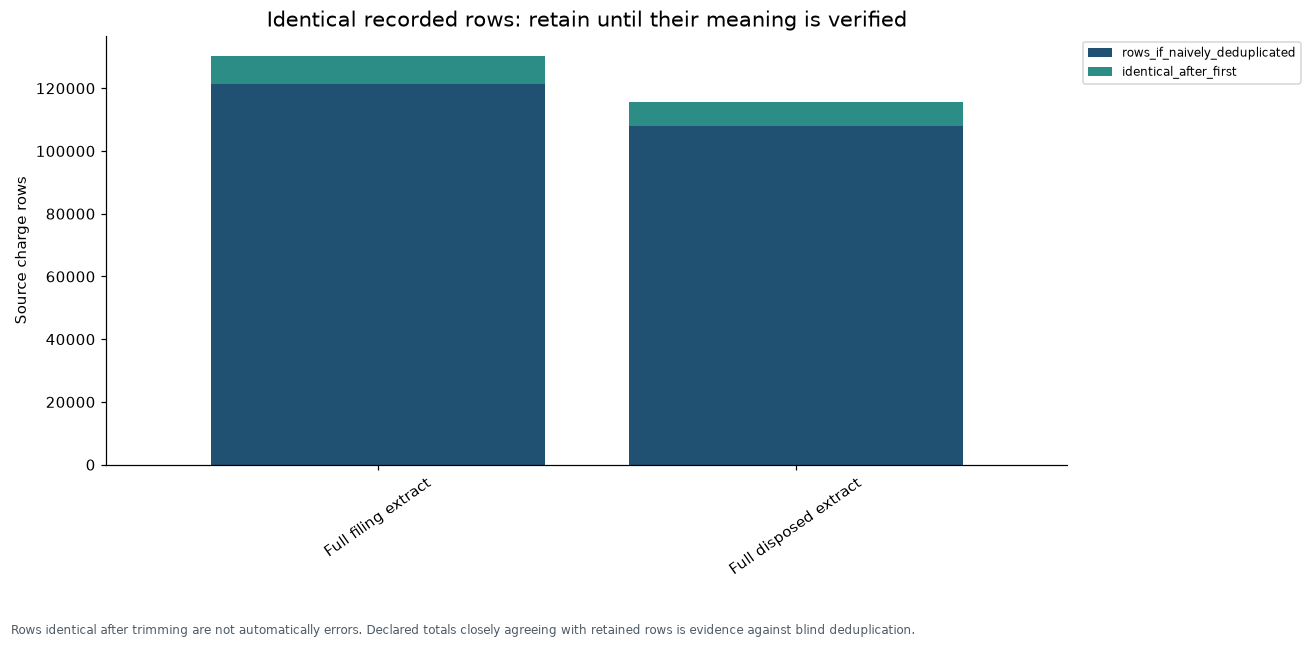

In [5]:
duplicate_headers=headers.loc[headers.duplicate_label|headers.trimmed_header.str.startswith('Unnamed_')]
table('duplicate_and_empty_header_positions',duplicate_headers,rows=20)
agreement=[]
for name,frame in [('Filed full extract',f_all),('Disposed full extract',d_all)]:
    check=frame.groupby('case_person').agg(observed_rows=('case_id','size'),declared=('declared_charge_count','first'),
                                         declared_variants=('declared_charge_count','nunique'))
    check['rows_equal_declared']=check.observed_rows.eq(check.declared)
    agreement.append({'extract':name,'cases':len(check),'rows_equal_declared':int(check.rows_equal_declared.sum()),
       'rows_below_declared':int(check.observed_rows.lt(check.declared).sum()),'rows_above_declared':int(check.observed_rows.gt(check.declared).sum()),
       'conflicting_declared_totals':int(check.declared_variants.gt(1).sum())})
table('declared_charge_total_vs_observed_rows',pd.DataFrame(agreement))
repeat=pd.DataFrame({'population':['Full filing extract','Full disposed extract'],
 'primary_rows':[len(f_all),len(d_all)],
 'identical_after_first':[int(f_all.exact_repeated_export.sum()),int(d_all.exact_repeated_export.sum())]})
repeat['rows_if_naively_deduplicated']=repeat.primary_rows-repeat.identical_after_first
table('identical_row_removal_sensitivity',repeat)
fig,ax=stacked(repeat.set_index('population')[['rows_if_naively_deduplicated','identical_after_first']],
              'Identical recorded rows: retain until their meaning is verified')
ax.set_ylabel('Source charge rows')
finish(fig,'01_repeated_rows','Rows identical after trimming are not automatically errors. Declared totals closely agreeing with retained rows is evidence against blind deduplication.')
note(f'{int(F.severe_shift.sum()+D.severe_shift.sum()):,} shifted rows and {int(F.unattached_row.sum()+D.unattached_row.sum()):,} unattached rows across the charge extracts are quarantined; original rows remain in the workbooks. Repeated rows remain in primary charge counts because no sequence identifier proves they are redundant.')

## 2. Missing, Unknown, unmapped, and invalid are different

**Purpose:** make missingness visible before any demographic, class, judge, or money comparison. Field blank rates use their stated row populations; explicit Unknown and unverified codes are counted separately.

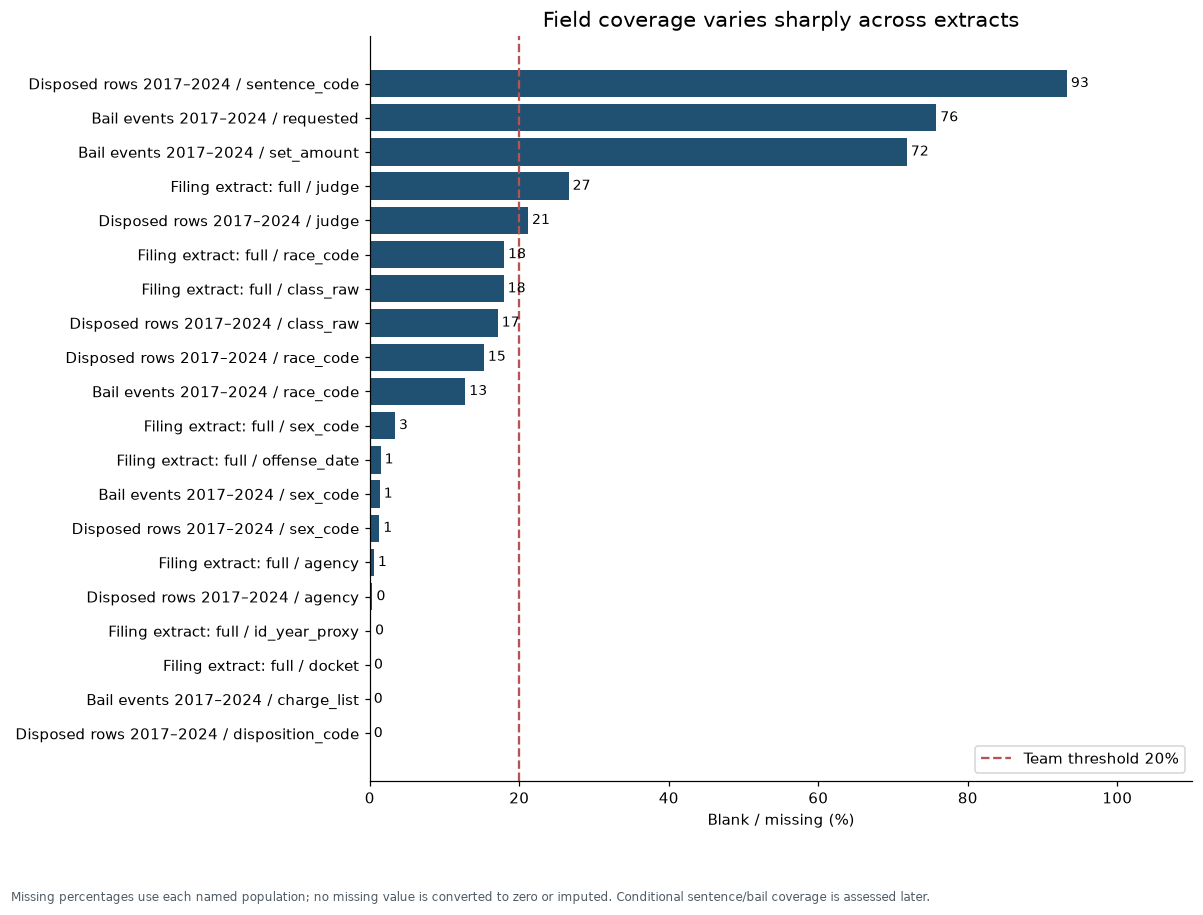

In [6]:
fig,ax=barh(coverage.set_index(coverage.population+' / '+coverage.field).missing_pct,
 'Field coverage varies sharply across extracts','Blank / missing (%)')
ax.axvline(20,color=COLORS[3],ls='--',label='Team threshold 20%');ax.legend()
finish(fig,'02_field_missingness','Missing percentages use each named population; no missing value is converted to zero or imputed. Conditional sentence/bail coverage is assessed later.')
codes=[]
for name,frame in [('Full filing extract',f_all),('Disposed 2017–2024',d),('Bail 2017–2024',b)]:
    for field in ['race_code','sex_code']:
        for value,count in frame[field].fillna('Missing').value_counts().items():
            codes.append({'population':name,'field':field,'source_value':value,'rows':int(count)})
table('demographic_raw_values_and_missing',pd.DataFrame(codes),rows=45)
table('source_class_values_and_missing',pd.concat({'Filed full':f_all.source_class.value_counts(),
                                                'Disposed in window':d.source_class.value_counts()},axis=1).fillna(0))
note('Missing race, explicit U, and unmapped race codes remain separate. In particular, C/CV/EI/I are not silently assigned a meaning from another county. Missing and nonstandard severity codes are not promoted to felony.')

## 3. Date abnormalities and the absent filing date

**Purpose:** show malformed centuries, dates after the fixed review date, and impossible recorded chronology. A successful parser does not validate a date. No offense-to-initiation or filing-to-disposition duration can be calculated.

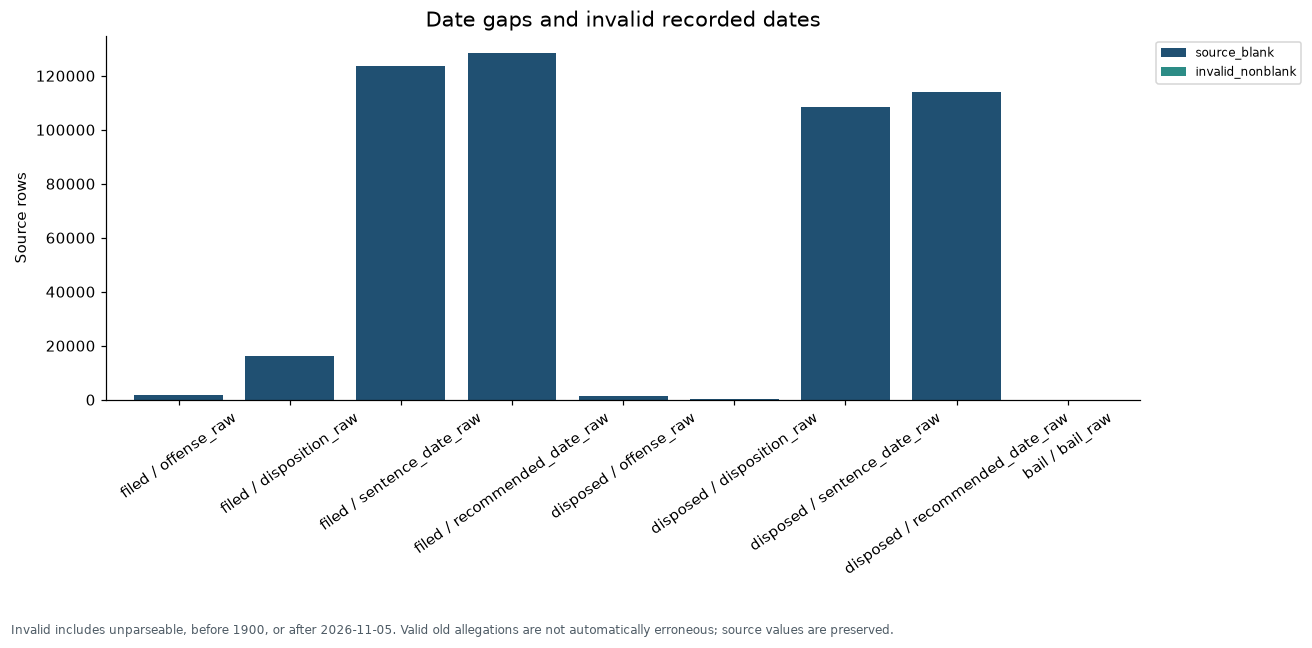

In [7]:
quality=pd.DataFrame(date_audit)
fig,ax=stacked(quality.set_index(quality.extract+' / '+quality.field)[['source_blank','invalid_nonblank']],
 'Date gaps and invalid recorded dates')
ax.set_ylabel('Source rows')
finish(fig,'03_date_quality','Invalid includes unparseable, before 1900, or after 2026-11-05. Valid old allegations are not automatically erroneous; source values are preserved.')
d['offense_to_disposition_days']=(d.disposition_date-d.offense_date).dt.days
table('date_chronology_flags',pd.Series({'disposition_rows_in_window':len(d),
 'disposition_before_offense':int(d.offense_to_disposition_days.lt(0).sum()),
 'offense_date_missing_or_invalid':int(d.offense_date.isna().sum()),
 'filing_date_columns_present':0,'full_filing_rows_without_proxy_year':int(f_all.id_year_proxy.isna().sum())},name='rows_or_fields'))
table('filed_extract_ID_year_categories',f_all.id_year_category.value_counts().sort_index().to_frame('charge_rows'),rows=40)
note(f'{d.offense_to_disposition_days.lt(0).sum():,} disposition-window charge rows have disposition before offense. Filing dates are not supplied; none are reconstructed from IDs.')

## 4. Allegations in the filing extract: full composition and proxy-year trends

**Purpose:** identify the charges driving the supplied filing extract and show an explicitly unverified ID-year sensitivity. The complete literal-description frequency table is exported. A code’s most common description supplies its chart label; descriptions are not treated as a validated offense-category taxonomy.

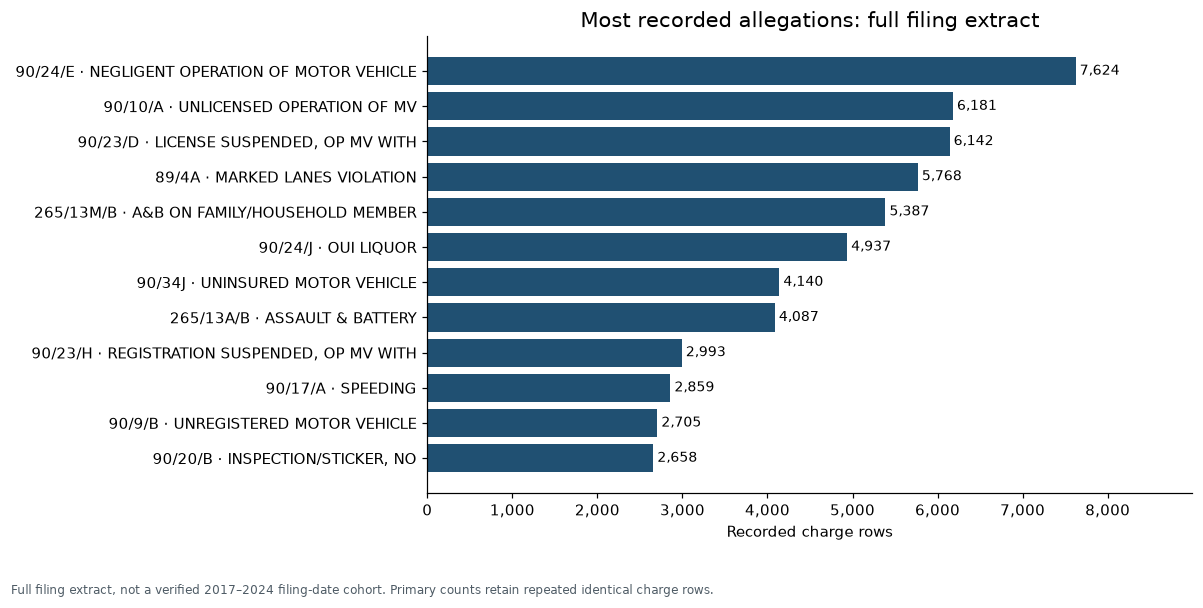

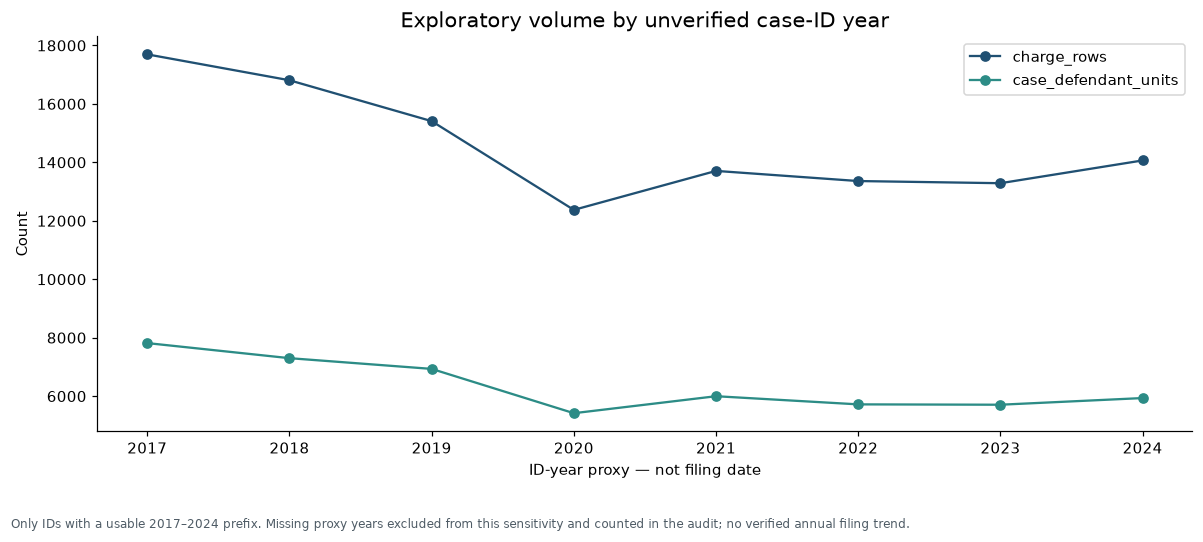

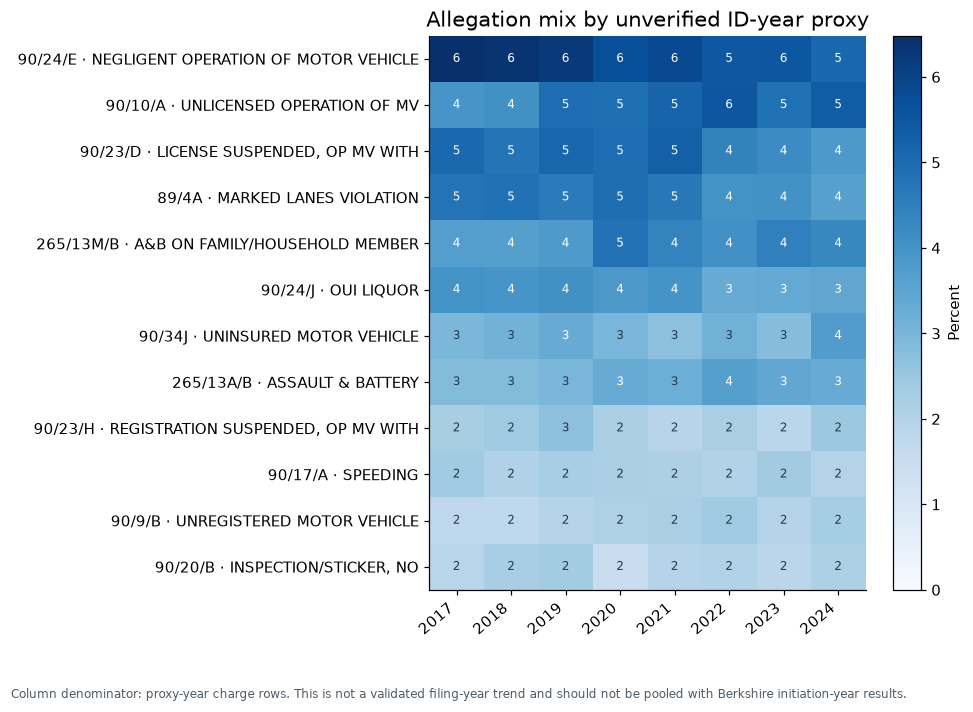

In [8]:
literal=f_all.groupby('charge_description',dropna=False).agg(charge_rows=('case_id','size'),cases=('case_person','nunique'),people=('person_id','nunique')).sort_values('charge_rows',ascending=False)
literal['share_full_filing_extract_pct']=literal.charge_rows/len(f_all)*100
table('all_unique_charge_descriptions_full_extract',literal,rows=25)
counts=f_all.charge_code.value_counts();top_codes=counts.head(12).index
table('charge_code_full_extract_frequencies',counts.rename('charge_rows'),rows=25)
fig,ax=barh(counts.head(12).rename(index=labels),'Most recorded allegations: full filing extract')
finish(fig,'04_top_filing_codes_full','Full filing extract, not a verified 2017–2024 filing-date cohort. Primary counts retain repeated identical charge rows.')
proxy=f.groupby('id_year_proxy').agg(charge_rows=('case_id','size'),case_defendant_units=('case_person','nunique'),people=('person_id','nunique'))
table('ID_year_proxy_volume',proxy)
fig,ax=plt.subplots(figsize=(11,5));proxy[['charge_rows','case_defendant_units']].plot(ax=ax,marker='o')
ax.set(title='Exploratory volume by unverified case-ID year',xlabel='ID-year proxy — not filing date',ylabel='Count')
finish(fig,'05_ID_year_proxy_volume','Only IDs with a usable 2017–2024 prefix. Missing proxy years excluded from this sensitivity and counted in the audit; no verified annual filing trend.')
year_codes=pd.crosstab(f.charge_code,f.id_year_proxy)
table('charge_code_ID_year_proxy_counts',year_codes,rows=20)
shares=year_codes.div(year_codes.sum(axis=0),axis=1)*100
fig,ax=heatmap(shares.reindex(top_codes).rename(index=labels),'Allegation mix by unverified ID-year proxy',percent=True,annotate=True)
finish(fig,'06_code_ID_year_proxy_mix','Column denominator: proxy-year charge rows. This is not a validated filing-year trend and should not be pooled with Berkshire initiation-year results.')
note(f'The full clean filing extract has {f_all.charge_description.nunique():,} literal descriptions and {f_all.charge_code.nunique():,} charge codes. Complete frequencies retain Missing where present; the top-code graphs do not cover every allegation.')

## 5. Monthly patterns using actual offense dates

**Purpose:** monthly analysis is possible for recorded offense dates, not filing dates. These charts select full filing-extract rows whose valid offense date lies in 2017–2024. They describe allegations represented in this extraction, not complete crimes occurring in the county or a filing trend.

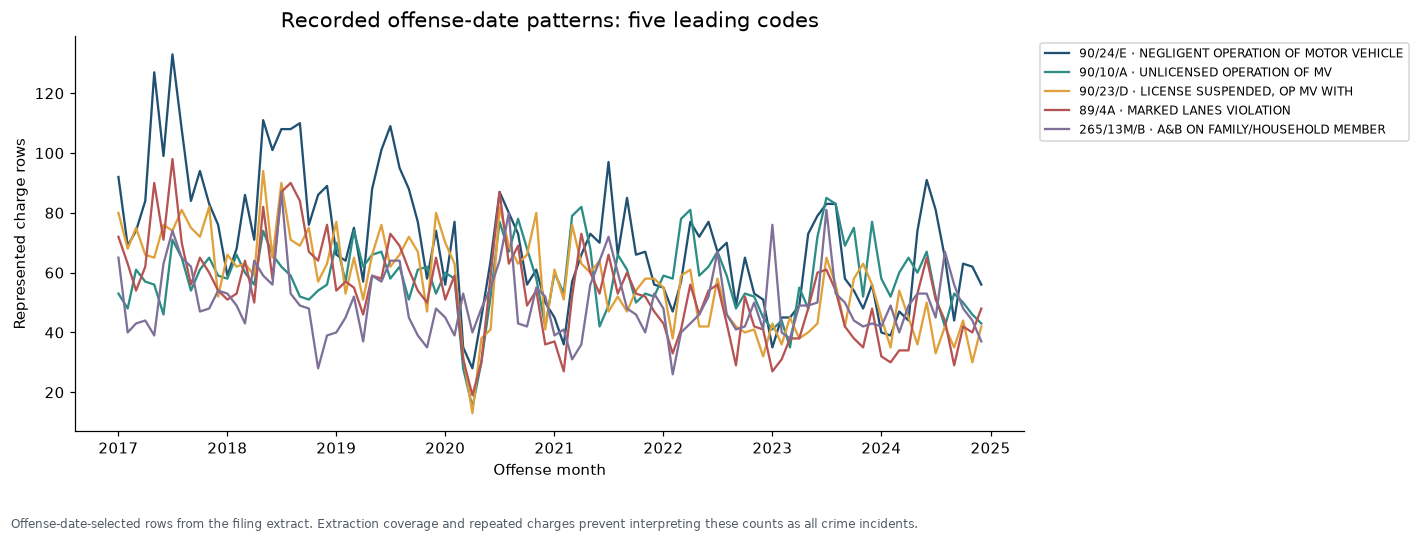

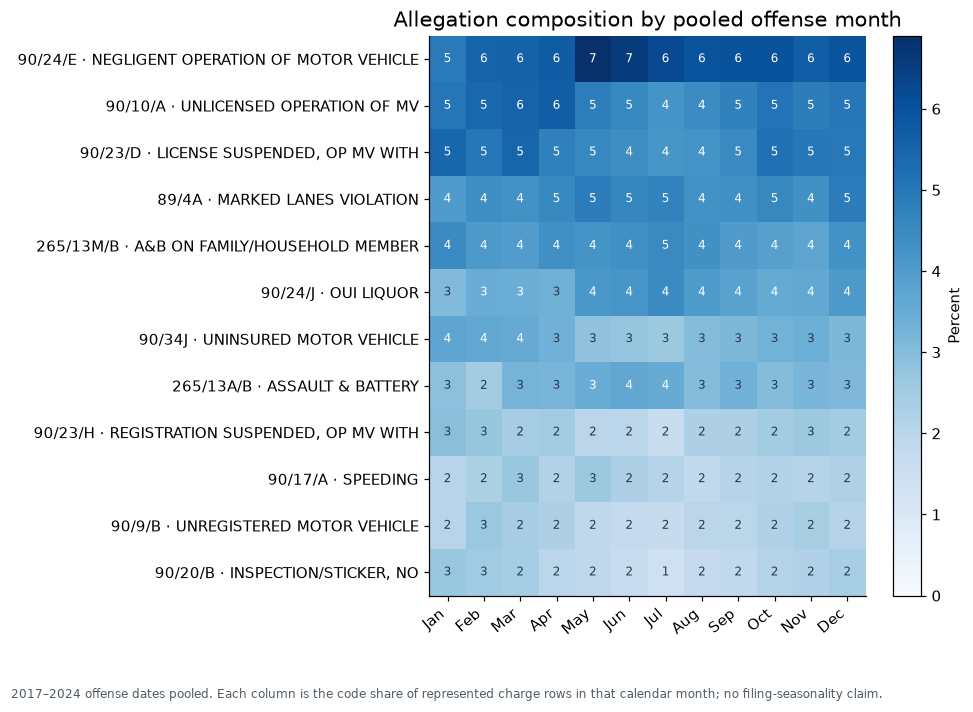

In [9]:
offense_rows=f_all.loc[in_window(f_all.offense_date)].copy()
monthly=pd.crosstab(offense_rows.offense_date.dt.to_period('M'),offense_rows.charge_code).reindex(pd.period_range('2017-01','2024-12',freq='M'),fill_value=0)
table('offense_date_monthly_code_counts',monthly,rows=12)
fig,ax=plt.subplots(figsize=(13,5))
for c in counts.head(5).index:ax.plot(monthly.index.to_timestamp(),monthly.get(c,pd.Series(0,index=monthly.index)),label=labels[c][:55])
ax.set(title='Recorded offense-date patterns: five leading codes',xlabel='Offense month',ylabel='Represented charge rows')
ax.legend(bbox_to_anchor=(1.01,1),loc='upper left',fontsize=8)
finish(fig,'07_offense_month_timeline','Offense-date-selected rows from the filing extract. Extraction coverage and repeated charges prevent interpreting these counts as all crime incidents.')
pooled=pd.crosstab(offense_rows.charge_code,offense_rows.offense_date.dt.month).reindex(columns=range(1,13),fill_value=0)
table('offense_date_pooled_month_counts',pooled,rows=20)
mix=pooled.div(pooled.sum(axis=0),axis=1)*100
fig,ax=heatmap(mix.reindex(top_codes).rename(index=labels).rename(columns={i:calendar.month_abbr[i] for i in range(1,13)}),
 'Allegation composition by pooled offense month',percent=True,annotate=True)
finish(fig,'08_offense_pooled_month_mix','2017–2024 offense dates pooled. Each column is the code share of represented charge rows in that calendar month; no filing-seasonality claim.')
note(f'{len(offense_rows):,} filing-extract rows have valid offense dates in 2017–2024. Offense-to-initiation delay remains unanswerable because the second date is absent.')

## 6. Source offense class, including Missing and unmapped codes

**Purpose:** show the severity information actually supplied. Nonstandard codes are not mapped using another county’s dictionary or a master dataset. Within-class seriousness and broad categories cannot be established from these columns alone.

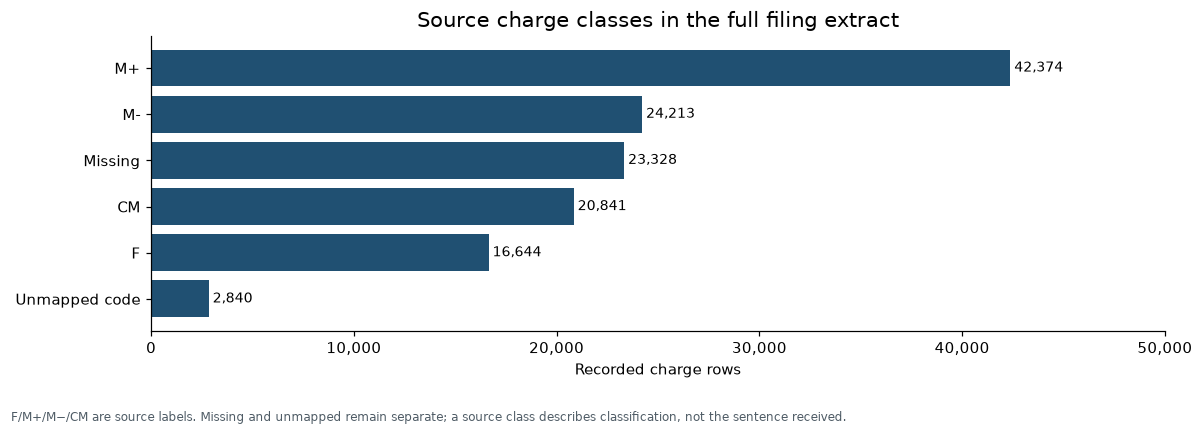

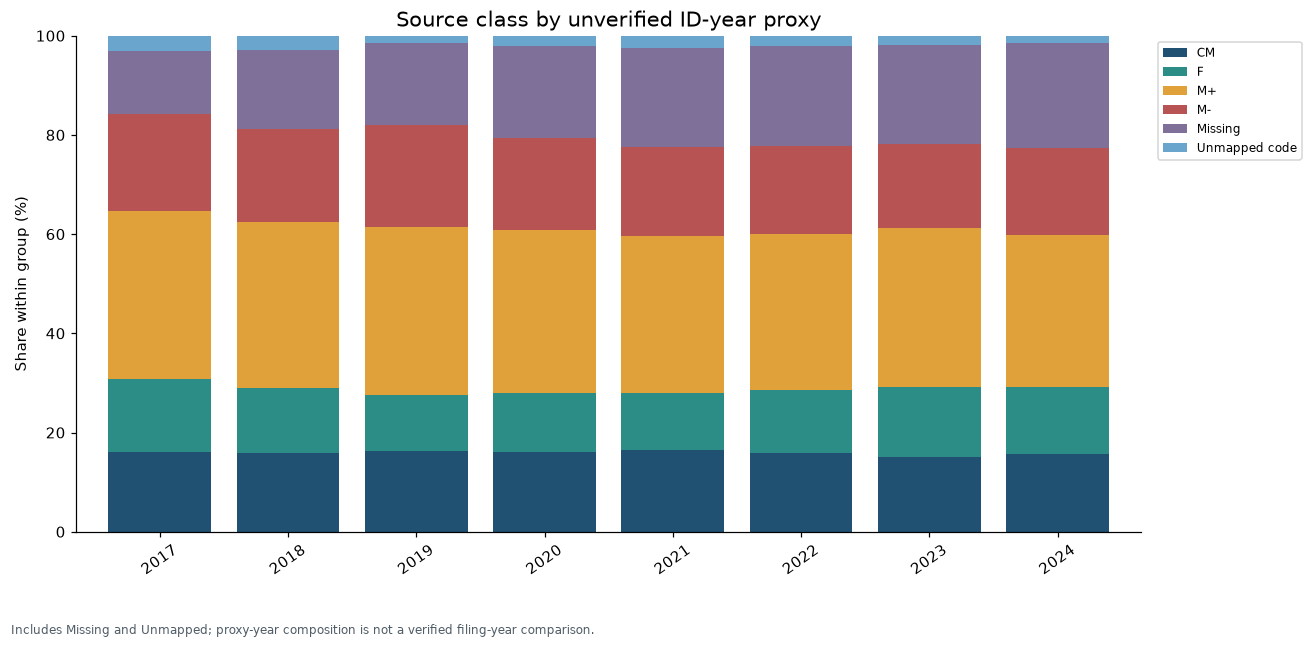

In [10]:
classes=f_all.class_plot.value_counts().reindex(['F','M+','M-','CM','Missing','Unmapped code'],fill_value=0)
table('source_class_full_extract',classes.rename('charge_rows'))
fig,ax=barh(classes,'Source charge classes in the full filing extract')
finish(fig,'09_source_class_distribution','F/M+/M−/CM are source labels. Missing and unmapped remain separate; a source class describes classification, not the sentence received.')
class_year=pd.crosstab(f.id_year_proxy,f.class_plot)
fig,ax=stacked(class_year,'Source class by unverified ID-year proxy',percent=True)
finish(fig,'10_source_class_proxy_year','Includes Missing and Unmapped; proxy-year composition is not a verified filing-year comparison.')
case_classes=fc_all.case_class.value_counts()
table('case_highest_source_class_and_incompleteness',case_classes.rename('cases'))
note(f'{f_all.class_raw.isna().mean():.1%} of filing charge rows have Missing class and {f_all.class_unmapped.mean():.1%} have unmapped source codes. Cases with a known felony can retain a felony marker; missing/unmapped charges otherwise block a definite highest-class assignment.')

## 7. Recorded people and charge concentration

**Purpose:** distinguish many charge rows from many cases. The ranking uses the full filing extract and internal defendant IDs; chart labels use ranks. No names, guilt, recidivism, or cross-county identity is inferred. Removing identical rows is shown only as a sensitivity.

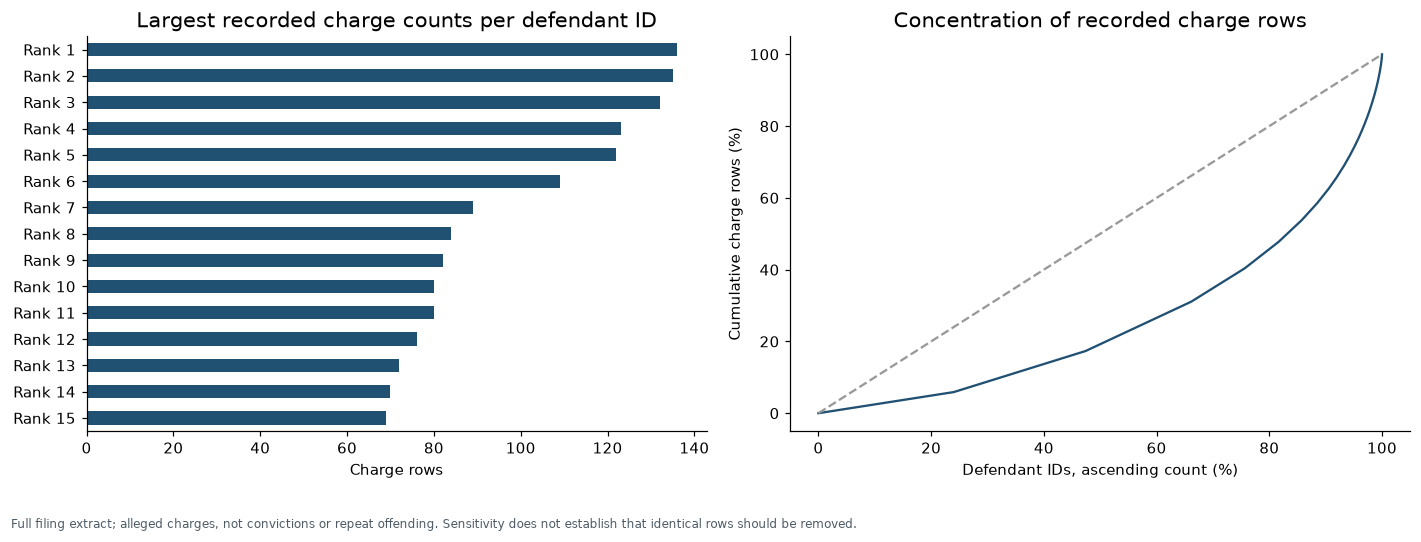

In [11]:
people=f_all.groupby('person_id').agg(charge_rows=('case_id','size'),cases=('case_person','nunique'),codes=('charge_code','nunique')).sort_values('charge_rows',ascending=False)
people['rows_if_identical_exports_removed']=f_all.loc[~f_all.exact_repeated_export].groupby('person_id').size()
table('highest_recorded_charge_counts_by_defendant_ID',people,rows=20)
fig,axs=plt.subplots(1,2,figsize=(13,5))
people.head(15).charge_rows.iloc[::-1].set_axis([f'Rank {i}' for i in range(15,0,-1)]).plot.barh(ax=axs[0],color=COLORS[0])
axs[0].set(title='Largest recorded charge counts per defendant ID',xlabel='Charge rows')
vals=np.sort(people.charge_rows.to_numpy());axs[1].plot(np.arange(len(vals)+1)/len(vals)*100,np.r_[0,np.cumsum(vals)/vals.sum()]*100)
axs[1].plot([0,100],[0,100],ls='--',color='#999');axs[1].set(title='Concentration of recorded charge rows',xlabel='Defendant IDs, ascending count (%)',ylabel='Cumulative charge rows (%)')
finish(fig,'11_charge_concentration','Full filing extract; alleged charges, not convictions or repeat offending. Sensitivity does not establish that identical rows should be removed.')
note(f'The highest-recorded defendant ID has {people.iloc[0].charge_rows:,.0f} charge rows across {people.iloc[0].cases:,.0f} case units in the full filing extract.')

## 8. Race and recorded sex: class and allegation composition

**Purpose:** counts and within-group composition answer different questions. Use the full filing extract with Missing/Unknown/unmapped categories preserved. No population denominator or control for prior record exists. A demographic group needs 30 rows; charge-by-group cells under 30 are suppressed.

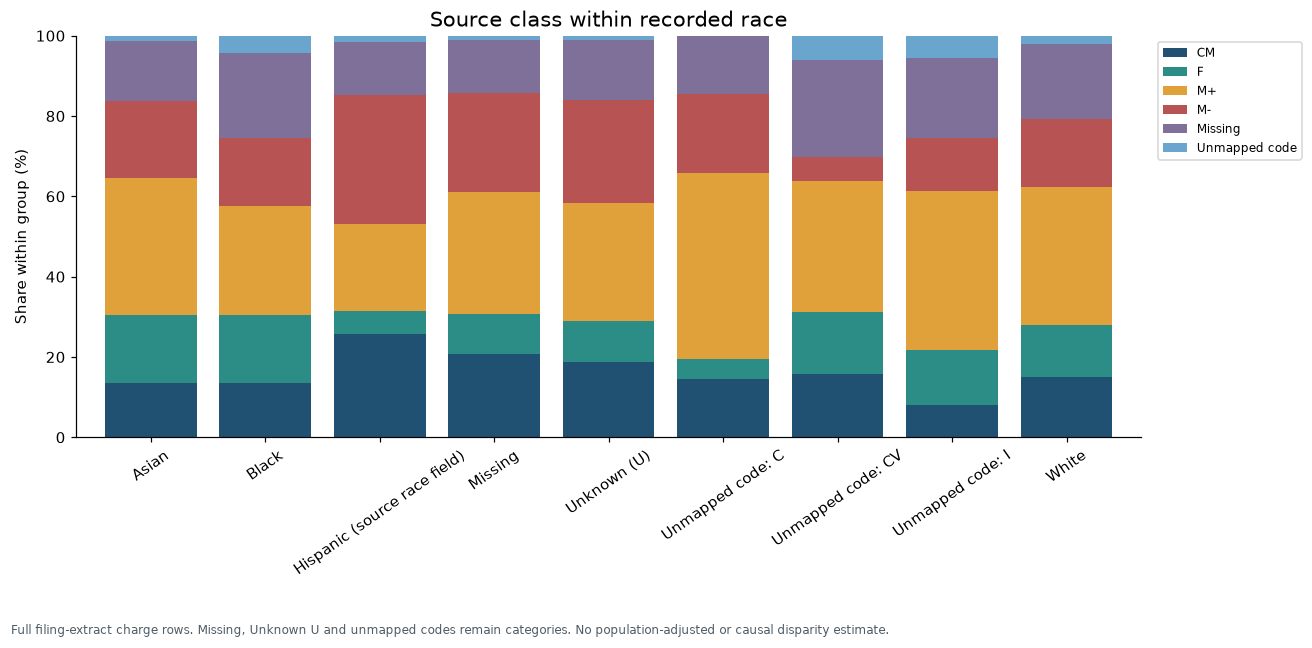

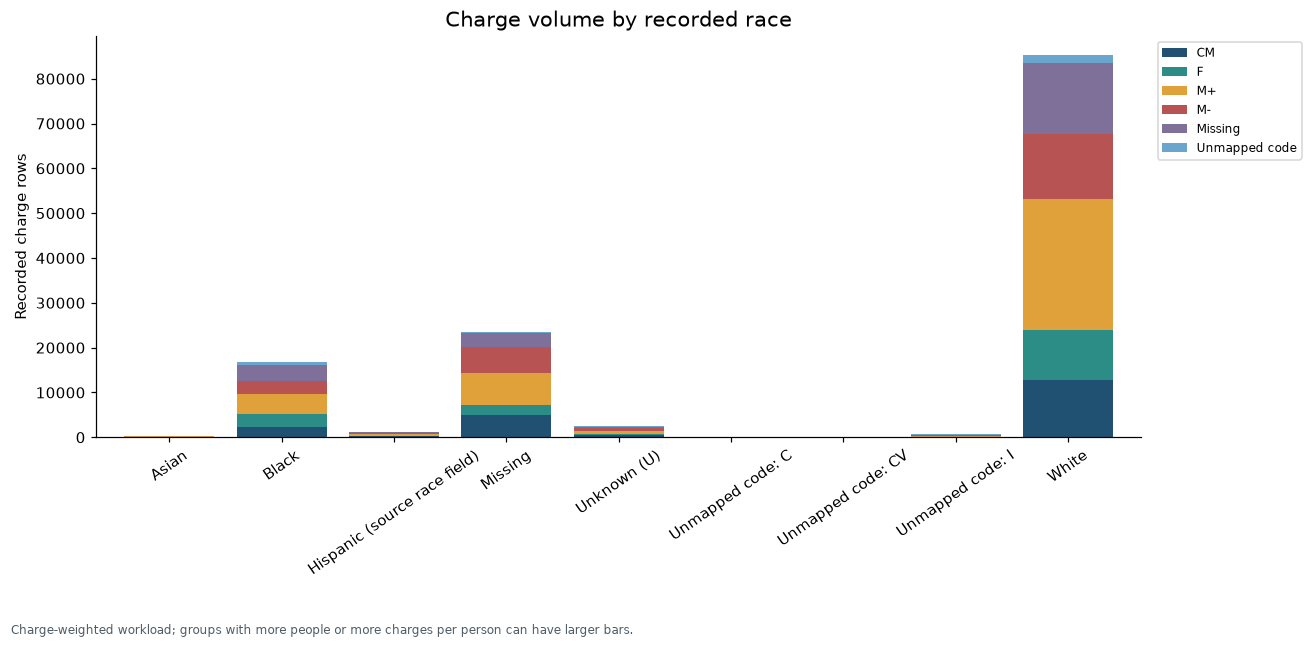

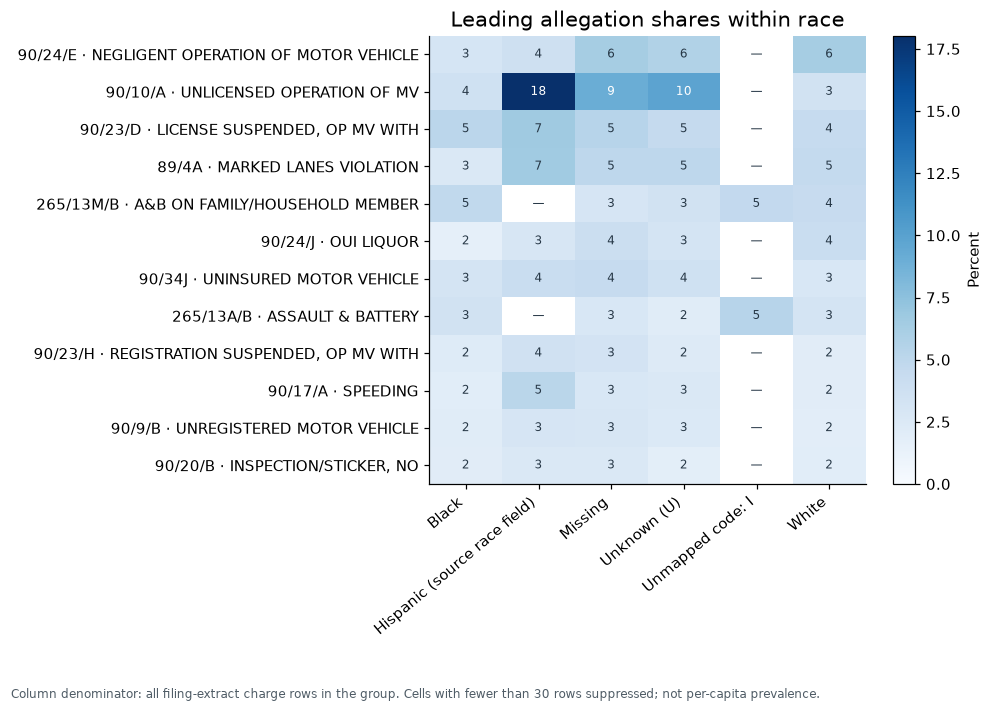

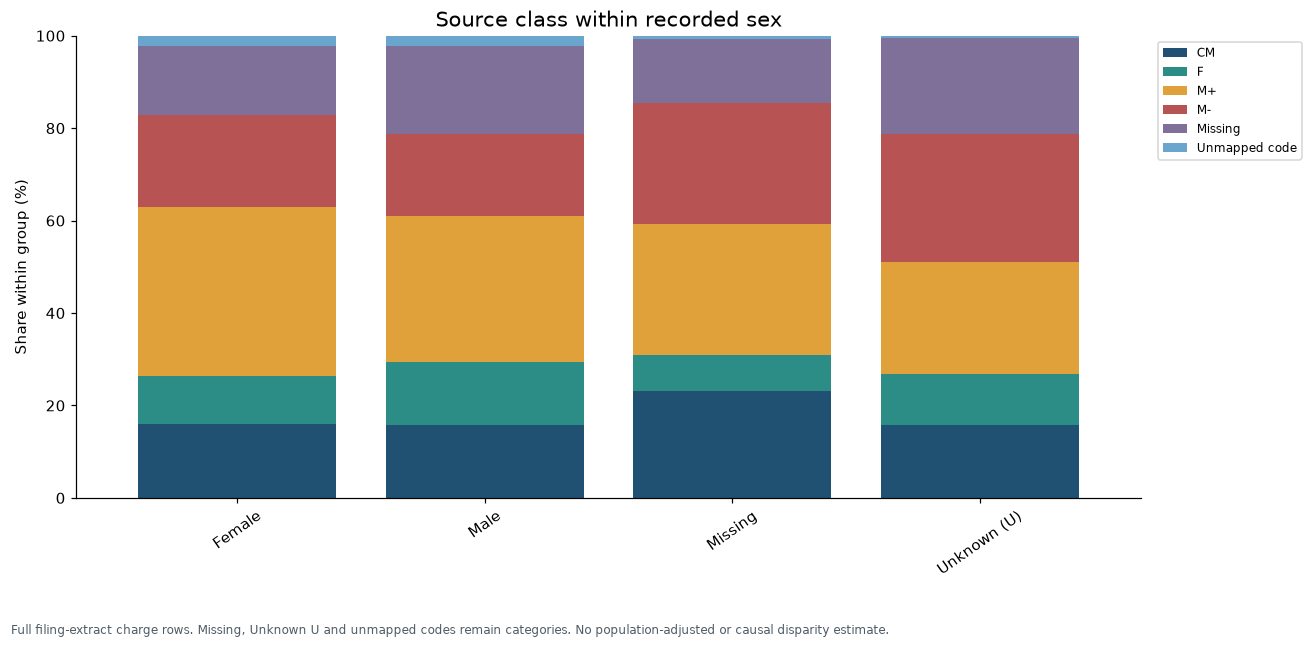

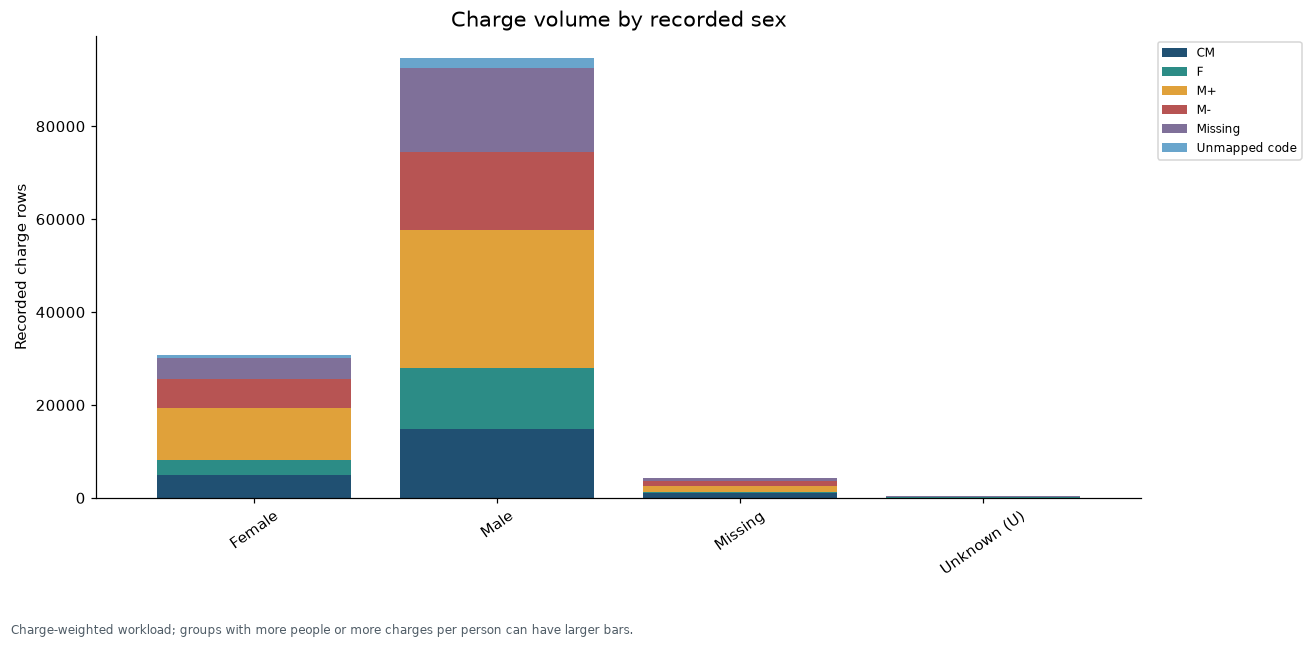

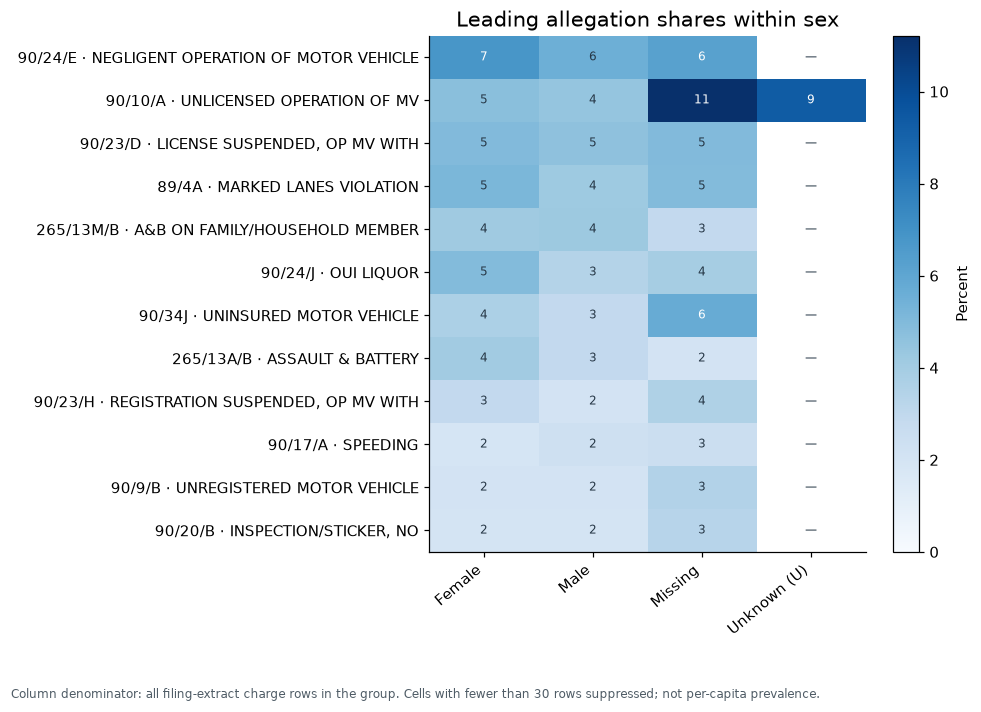

In [12]:
for group in ['race','sex']:
    ct=pd.crosstab(f_all[group],f_all.class_plot)
    table(f'filing_class_by_{group}',ct,rows=30)
    eligible=ct.sum(axis=1).loc[lambda s:s>=MIN_CELL].index
    fig,ax=stacked(ct.loc[eligible],f'Source class within recorded {group}',percent=True)
    finish(fig,f'12_{group}_class_mix','Full filing-extract charge rows. Missing, Unknown U and unmapped codes remain categories. No population-adjusted or causal disparity estimate.')
    fig,ax=stacked(ct.loc[eligible],f'Charge volume by recorded {group}')
    finish(fig,f'13_{group}_class_volume','Charge-weighted workload; groups with more people or more charges per person can have larger bars.')
    crosstab=pd.crosstab(f_all.charge_code,f_all[group]);table(f'charge_code_by_{group}',crosstab,rows=15)
    matrix=crosstab.div(crosstab.sum(axis=0),axis=1)*100
    matrix=matrix.reindex(top_codes).where(crosstab.reindex(top_codes)>=MIN_CELL).rename(index=labels)
    fig,ax=heatmap(matrix,f'Leading allegation shares within {group}',percent=True,annotate=True)
    finish(fig,f'14_{group}_allegations','Column denominator: all filing-extract charge rows in the group. Cells with fewer than 30 rows suppressed; not per-capita prevalence.')
note('Race and sex remain source administrative fields. Rare raw codes are preserved in full tables; no undocumented demographic mapping or gender identity inference is imposed.')

## 9. Disposition codes: overall, by year, and by allegation

**Purpose:** preserve original codes and descriptions before using a provisional common crosswalk. This population uses actual disposition dates in 2017–2024. Civil responsibility, juvenile adjudication, CWOF, and pretrial probation remain distinct.

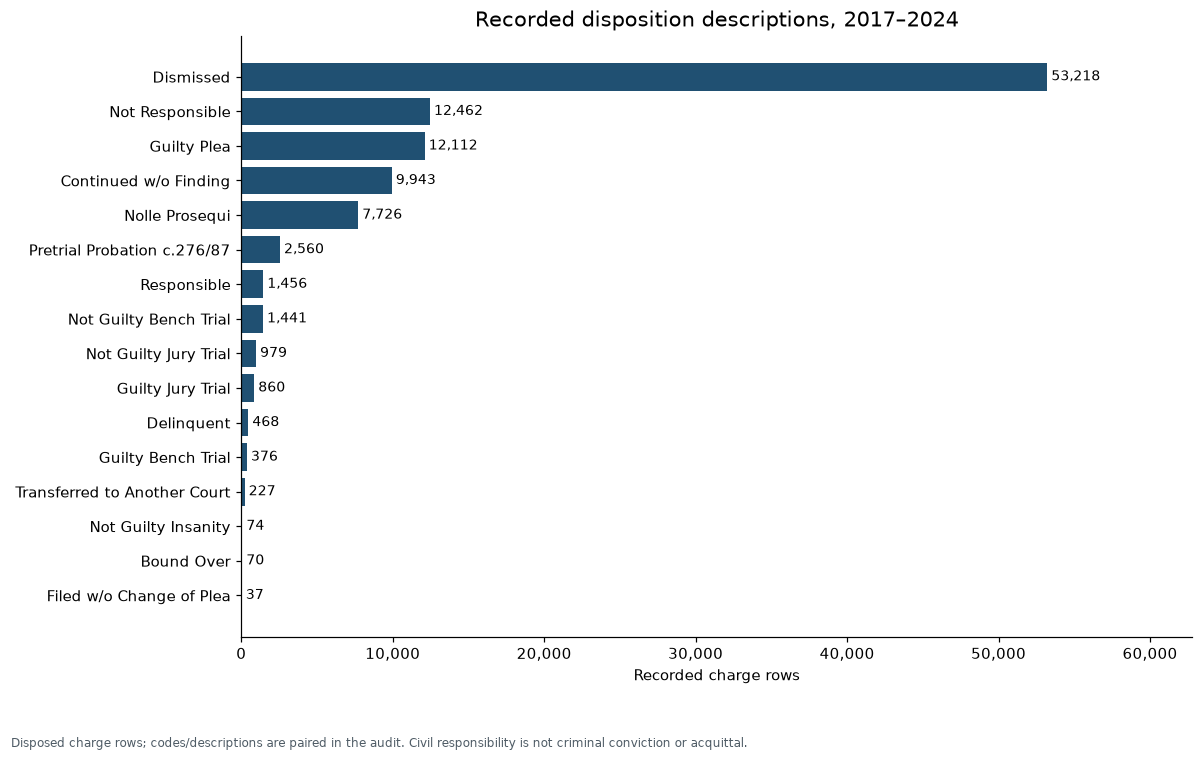

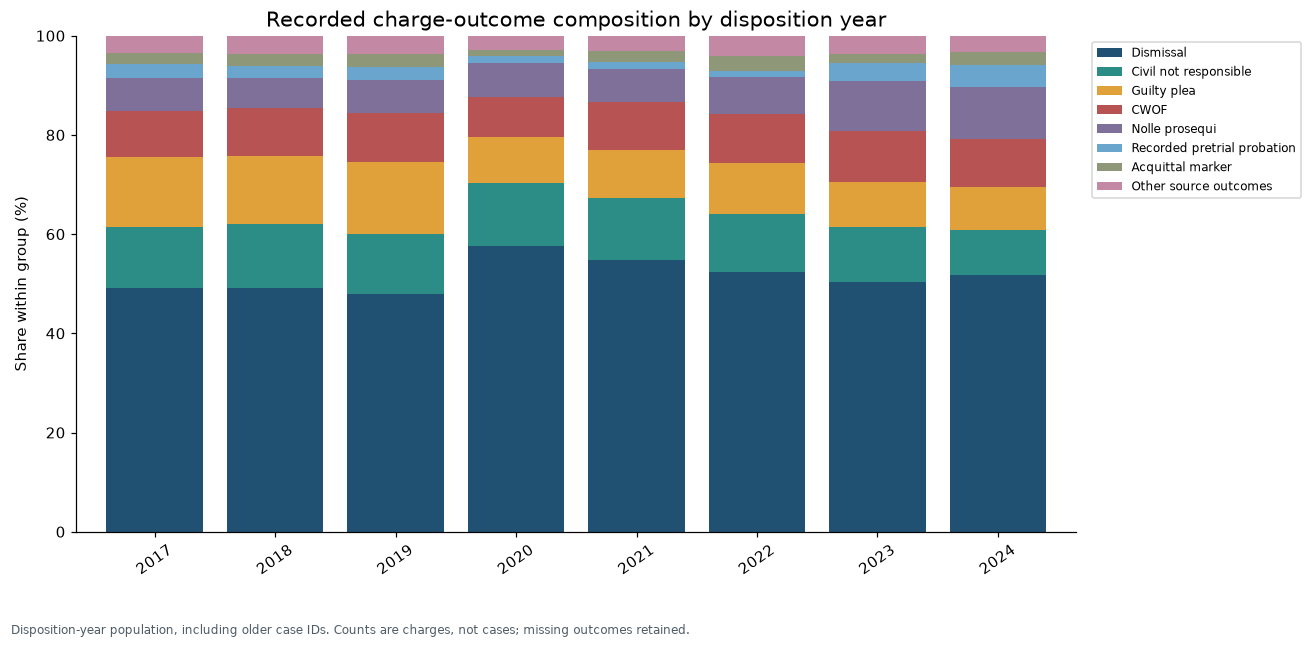

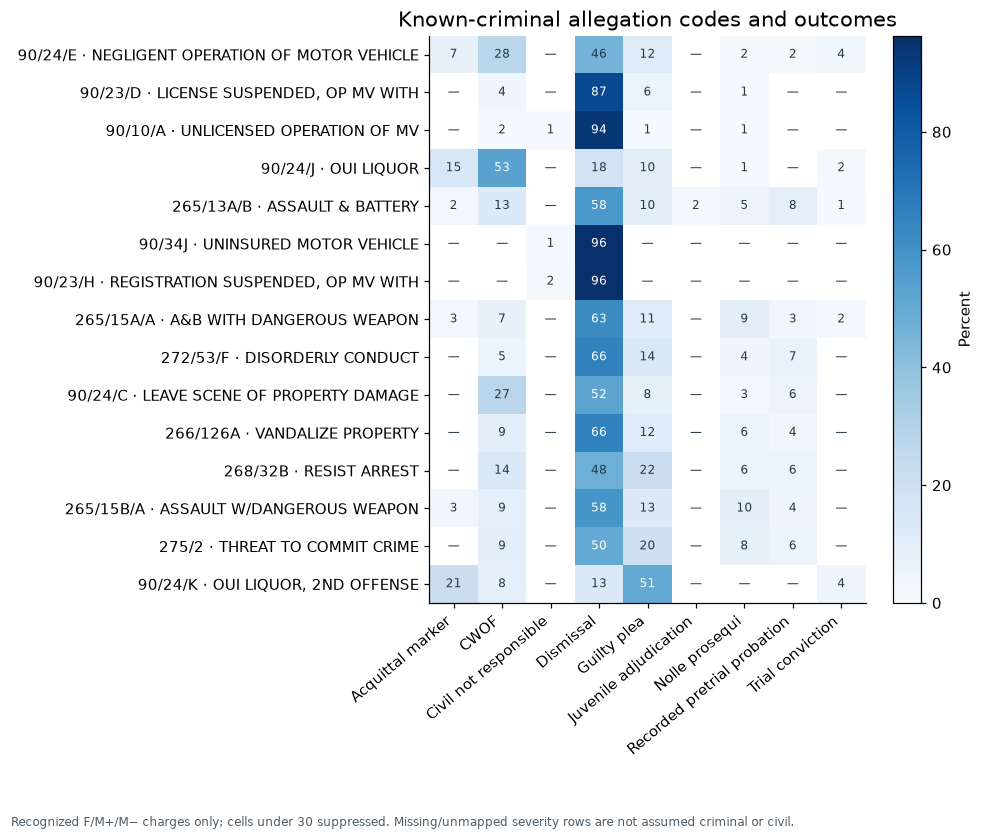

In [13]:
raw_out=d.disposition_description.fillna('Missing').value_counts()
table('raw_disposition_descriptions',raw_out.rename('charge_rows'),rows=40)
table('disposition_code_by_year',pd.crosstab(d.disposition_date.dt.year,d.disposition_code.fillna('Missing')))
fig,ax=barh(raw_out.head(16),'Recorded disposition descriptions, 2017–2024')
finish(fig,'15_raw_dispositions','Disposed charge rows; codes/descriptions are paired in the audit. Civil responsibility is not criminal conviction or acquittal.')
year=pd.crosstab(d.disposition_date.dt.year,d.outcome)
table('outcome_by_disposition_year',year)
leaders=d.outcome.value_counts().head(7).index
plot=year.reindex(columns=leaders,fill_value=0);plot['Other source outcomes']=year.sum(axis=1)-plot.sum(axis=1)
fig,ax=stacked(plot,'Recorded charge-outcome composition by disposition year',percent=True)
finish(fig,'16_outcome_year_mix','Disposition-year population, including older case IDs. Counts are charges, not cases; missing outcomes retained.')
known=d.loc[d.known_criminal]
ct=pd.crosstab(known.charge_code,known.outcome);table('known_criminal_code_vs_outcome_counts',ct,rows=20)
codes=known.charge_code.value_counts().head(15).index
hm=ct.div(ct.sum(axis=1),axis=0)*100;hm=hm.reindex(codes).where(ct.reindex(codes)>=MIN_CELL).rename(index=labels)
fig,ax=heatmap(hm,'Known-criminal allegation codes and outcomes',percent=True,annotate=True)
finish(fig,'17_code_outcome_mix','Recognized F/M+/M− charges only; cells under 30 suppressed. Missing/unmapped severity rows are not assumed criminal or civil.')
note(f'The leading disposition description is {raw_out.index[0]} ({raw_out.iloc[0]/len(d):.1%} of disposition-window charge rows). The denominator differs from the filing extract and should not be used as a filing-cohort resolution rate.')

## 10. Case-level outcomes, CWOF, pretrial probation, and pleas

**Purpose:** show one outcome per observed case unit as a separate view from charge-level results. Guilty Plea (`GPL`), CWOF (`CWF`), and Pretrial Probation (`PTP`) are explicitly separate source codes. PTP is a recorded outcome, not proof of participation in a named diversion program.

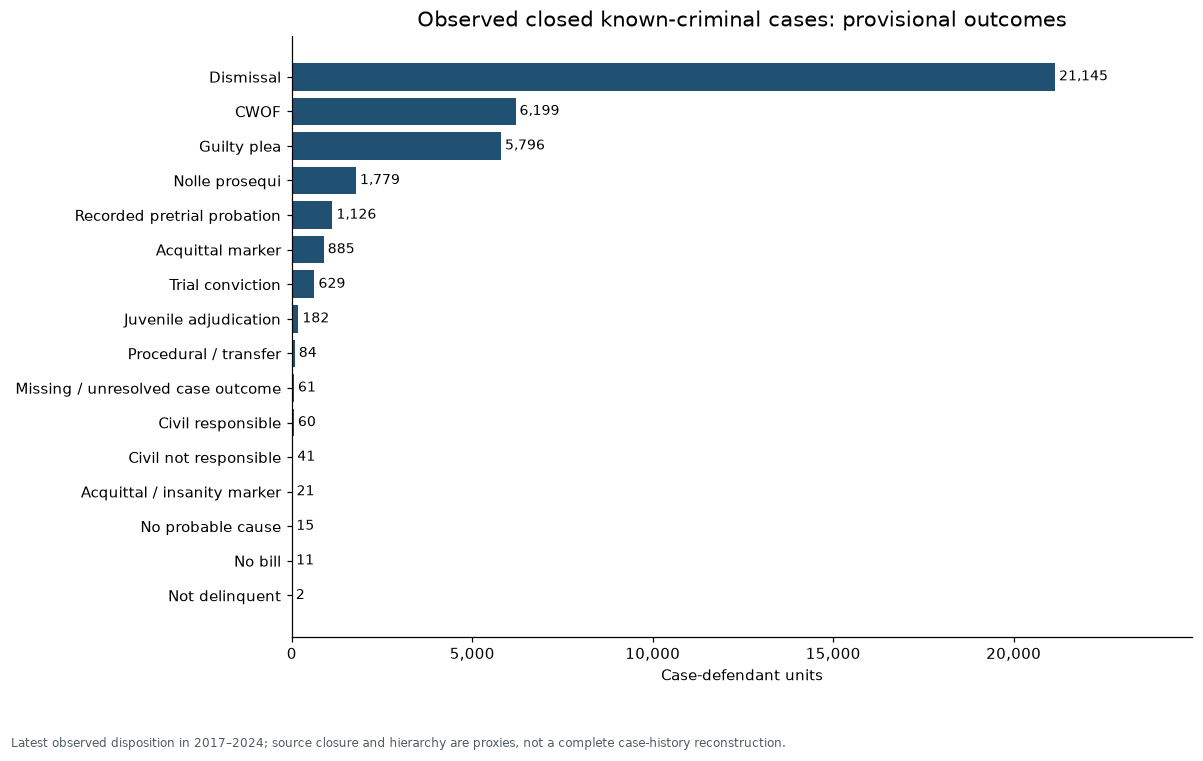

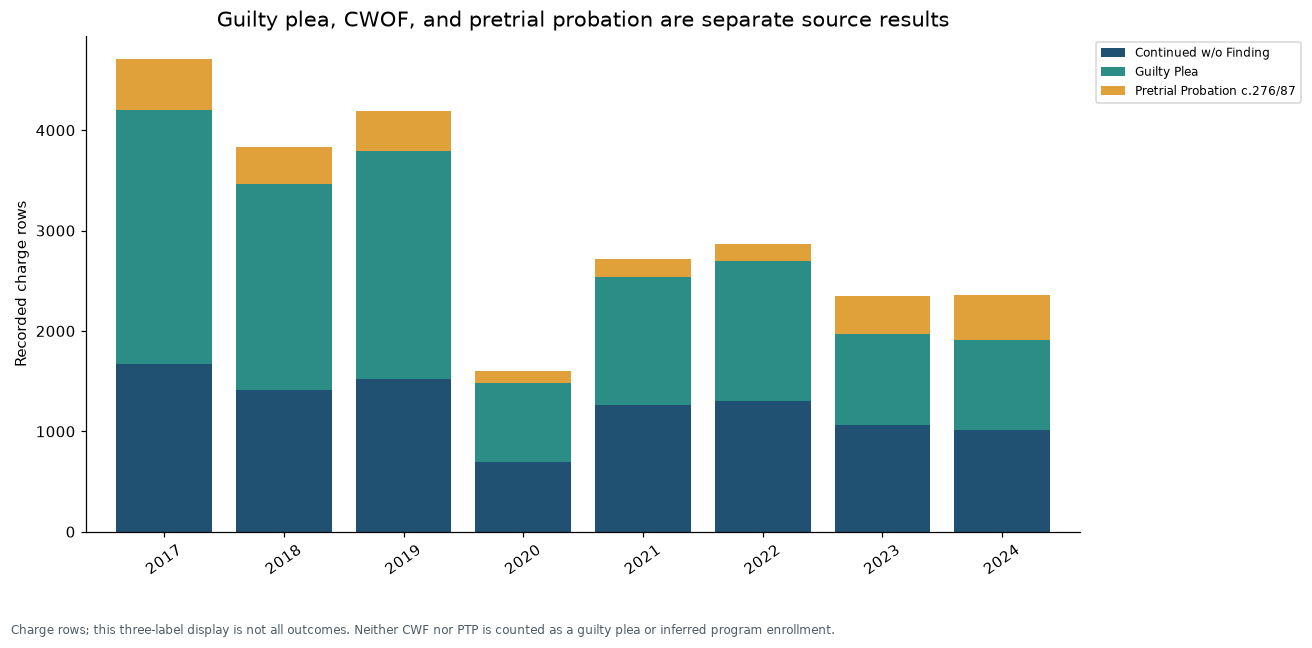

In [14]:
case_out=dc.outcome.value_counts().to_frame('cases');case_out['percent']=case_out.cases/len(dc)*100
table('case_outcome_distribution',case_out,rows=30)
fig,ax=barh(case_out.cases,'Observed closed known-criminal cases: provisional outcomes','Case-defendant units')
finish(fig,'18_case_outcomes','Latest observed disposition in 2017–2024; source closure and hierarchy are proxies, not a complete case-history reconstruction.')
special=d.loc[d.disposition_code.isin(['GPL','CWF','PTP'])]
table('guilty_plea_CWOF_pretrial_probation_by_year',pd.crosstab(special.disposition_date.dt.year,special.disposition_description))
fig,ax=stacked(pd.crosstab(special.disposition_date.dt.year,special.disposition_description),
 'Guilty plea, CWOF, and pretrial probation are separate source results')
finish(fig,'19_GPL_CWF_PTP_counts','Charge rows; this three-label display is not all outcomes. Neither CWF nor PTP is counted as a guilty plea or inferred program enrollment.')
note(f'{len(dc):,} known-criminal closed case units meet the case disposition-window rule. {dc.outcome_unresolved.mean():.1%} have an unresolved case outcome under the conservative crosswalk.')

## 11. Sentencing: explicit evidence and substantial missingness

**Purpose:** inspect what is actually supplied before computing incarceration/probation/fine rates. `F` means Filed, not Fine; Suspended does not establish probation. Case-level conviction-marker sentencing is incomplete, and unknown sentence types remain visible.

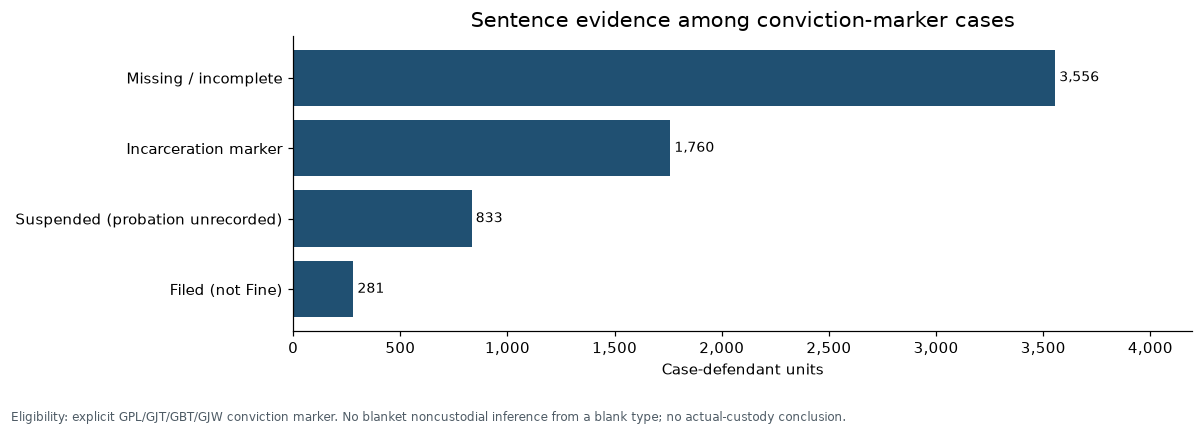

In [15]:
sentence=conv.sentence_group.value_counts().to_frame('conviction_marker_cases')
table('conviction_case_sentence_evidence',sentence,rows=25)
fig,ax=barh(sentence.iloc[:,0],'Sentence evidence among conviction-marker cases','Case-defendant units')
finish(fig,'20_sentence_evidence','Eligibility: explicit GPL/GJT/GBT/GJW conviction marker. No blanket noncustodial inference from a blank type; no actual-custody conclusion.')
missing=conv.sentence_group.eq('Missing / incomplete').mean()
note(f'Sentence type is Missing/incomplete for {missing:.1%} of conviction-marker case units. County-wide incarceration/probation/fine shares are withheld when the eligible-population missingness rule fails; Suspended/Filed do not repair absent probation/fine fields.')
cust=d_all.loc[d_all.conviction_marker&d_all.sentence_group.eq('Incarceration marker')].copy()
cust['term_value']=pd.to_numeric(cust['Imposed Actual MAX Term'],errors='coerce')
cust['unit_factor']=cust['Imposed Actual MAX Term Unit'].map({'Day':1,'Week':7,'Month':365.25/12,'Year':365.25,'Hour':1/24})
cust['actual_max_days']=(cust.term_value*cust.unit_factor).where(cust.term_value.ge(0))
cust_case=conv.loc[conv.sentence_group.eq('Incarceration marker')].copy()
cust_case['longest_recorded_actual_max_days']=cust.groupby('case_person').actual_max_days.max().reindex(cust_case.index)
table('recorded_actual_term_case_coverage',cust_case.longest_recorded_actual_max_days.describe().to_frame('days'))
table('actual_term_units',cust['Imposed Actual MAX Term Unit'].fillna('Missing').value_counts().to_frame('rows'))
note('The uniquely labeled Actual MAX term/unit can support available-record diagnostics. The two Imposed MAX Term Unit columns are not assigned guessed MIN/MAX meanings. Life/age-limited sentences and consecutive/concurrent structure cannot be reduced to a total finite case sentence here.')

## 12. Judges, courts, and demographic outcome patterns

**Purpose:** expose coverage and observed-record composition without ranking judges or attributing negotiated/prosecution outcomes to them. County-wide judge comparisons are withheld if missing judge coverage exceeds 20%. Raw named-judge counts are workload diagnostics only.

In [16]:
judge_missing=d.judge.isna().mean()
judges=d.judge.fillna('Missing').value_counts();table('recorded_judge_counts_with_missing',judges.rename('charge_rows'),rows=25)
fig,ax=barh(judges.head(15),'Recorded judge names and Missing: source workload only')
finish(fig,'21_judge_workload_coverage','Disposed charge rows; these are recorded name associations, not performance, fairness, or causal decision-maker effects.')
note(f'Judge is Missing on {judge_missing:.1%} of disposition-window charge rows. '+('This exceeds 20%; no county-wide judge decision-rate comparison is published.' if judge_missing>.2 else 'Named-record composition still requires case-mix and assignment caveats.'))
for group in ['race','sex']:
    ct=pd.crosstab(dc[group],dc.outcome);table(f'case_outcomes_by_{group}',ct,rows=30)
    eligible=ct.sum(axis=1).loc[lambda s:s>=MIN_CELL].index
    fig,ax=stacked(ct.loc[eligible],f'Case-level outcomes within recorded {group}',percent=True)
    finish(fig,f'22_case_outcome_{group}','Known-criminal closed case proxy; Missing and Unknown remain categories. No population exposure, prior record, or case-fact adjustment.')
court_mix=pd.crosstab(d.court.fillna('Missing'),d.class_plot)
table('court_class_composition',court_mix,rows=25)
big=court_mix.sum(axis=1).nlargest(10).index
fig,ax=stacked(court_mix.loc[big],'Courts see different source charge-class mixes',percent=True)
finish(fig,'23_court_class_mix','Disposed charge rows. Juvenile, diversion, superior and district labels represent different recorded settings, not interchangeable comparison populations.')

## 13. Offense-to-disposition time: measurable, but not processing time

**Purpose:** summarize the interval actually observable. This includes time before prosecution and is not filing-to-disposition time. Use one valid nonnegative interval per observed closed case, with Missing/invalid/negative cases counted separately.

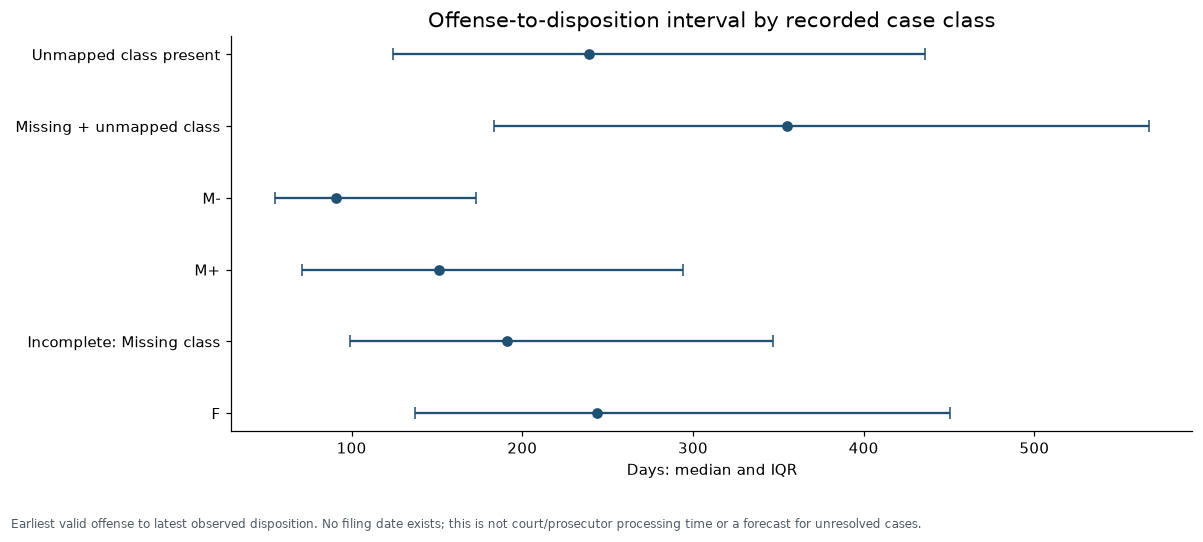

In [17]:
valid=dc.loc[dc.offense_to_disposition_days.ge(0)]
table('offense_to_disposition_case_summary',valid.offense_to_disposition_days.describe(percentiles=[.25,.5,.75,.9,.99]).to_frame('days'))
table('offense_to_disposition_case_exclusions',pd.Series({'eligible_case_units':len(dc),'usable':len(valid),
 'missing_or_invalid_offense_date':int(dc.offense_date.isna().sum()),'negative_interval':int(dc.offense_to_disposition_days.lt(0).sum())},name='cases'))
times=valid.groupby('case_class').offense_to_disposition_days.agg(n='size',median='median',p25=lambda s:s.quantile(.25),p75=lambda s:s.quantile(.75))
table('offense_to_disposition_by_case_class',times)
fig,ax=plt.subplots(figsize=(11,5));g=times.loc[times.n>=MIN_CELL]
ax.errorbar(g['median'],range(len(g)),xerr=[g['median']-g.p25,g.p75-g['median']],fmt='o',capsize=4)
ax.set_yticks(range(len(g)),g.index);ax.set(title='Offense-to-disposition interval by recorded case class',xlabel='Days: median and IQR')
finish(fig,'24_offense_to_disposition','Earliest valid offense to latest observed disposition. No filing date exists; this is not court/prosecutor processing time or a forecast for unresolved cases.')
note(f'Among {len(valid):,} usable case intervals, offense-to-disposition median is {valid.offense_to_disposition_days.median():,.0f} days. No offense-to-initiation or filing-to-disposition result is calculated.')

## 14. Bail: status landscape and repeated observations

**Purpose:** distinguish personal recognizance, recorded Bail, custody, revocation, and held statuses. The source has no Cash Only/Cash Surety distinction, no payment ledger, no custody-duration history, and no Crime Type column. Missing status remains explicit.

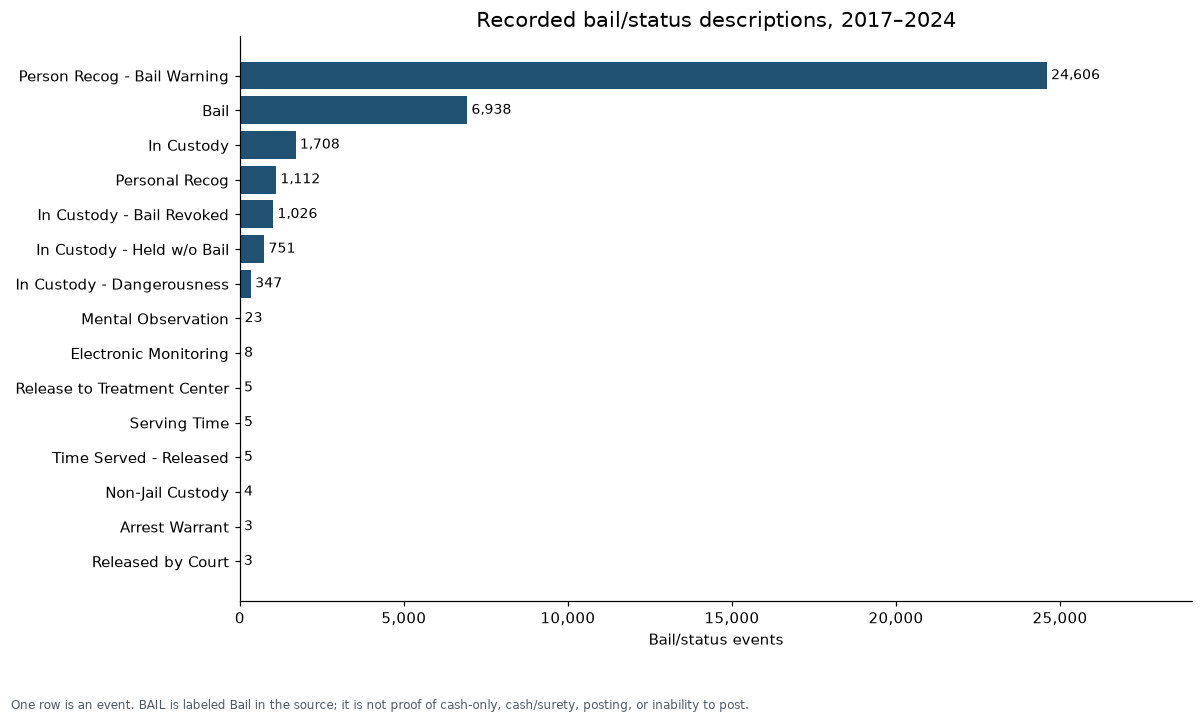

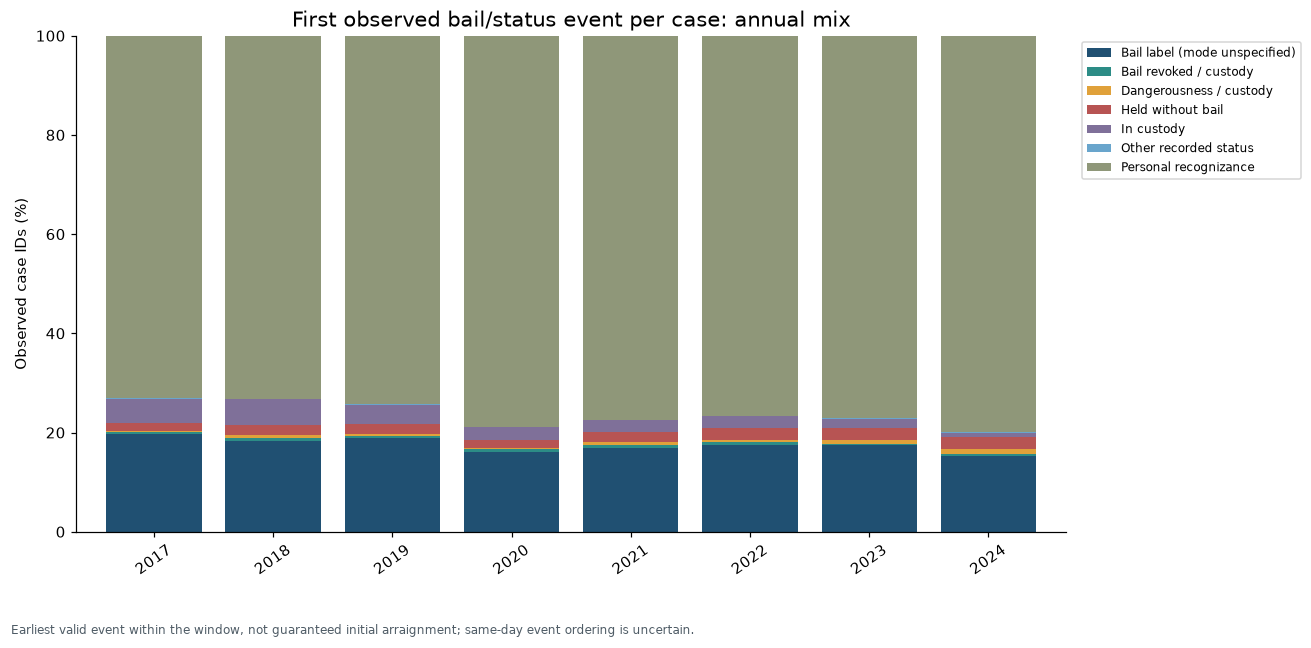

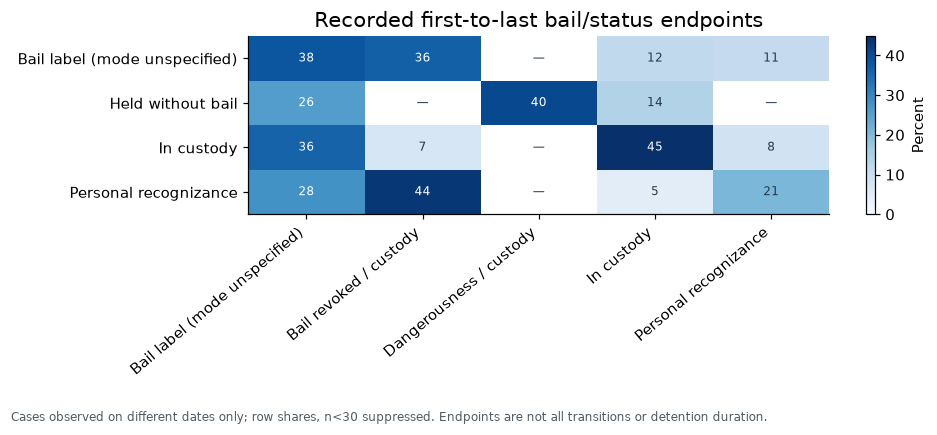

In [18]:
table('bail_code_description_pairs',b.groupby(['bail_code','bail_description'],dropna=False).size().to_frame('events'),rows=30)
status=b.bail_description.fillna('Missing').value_counts()
fig,ax=barh(status,'Recorded bail/status descriptions, 2017–2024','Bail/status events')
finish(fig,'25_bail_status_landscape','One row is an event. BAIL is labeled Bail in the source; it is not proof of cash-only, cash/surety, posting, or inability to post.')
table('bail_events_per_case',b.groupby('case_id').size().describe().to_frame('events'))
annual=pd.crosstab(first.bail_date.dt.year,first.status_group)
table('first_observed_bail_status_by_year',annual)
fig,ax=stacked(annual,'First observed bail/status event per case: annual mix',percent=True)
ax.set_ylabel('Observed case IDs (%)')
finish(fig,'26_first_bail_year','Earliest valid event within the window, not guaranteed initial arraignment; same-day event ordering is uncertain.')
first_date=b.groupby('case_id').bail_date.min();last_date=b.groupby('case_id').bail_date.max()
repeat_ids=first_date.index[last_date.gt(first_date)]
last=b.sort_values(['bail_date','bail_code_category','source_row']).drop_duplicates('case_id',keep='last')
endpoints=first.loc[first.case_id.isin(repeat_ids),['case_id','status_group']].merge(last[['case_id','status_group']],on='case_id',suffixes=('_first','_last'),validate='one_to_one')
transition=pd.crosstab(endpoints.status_group_first,endpoints.status_group_last)
table('bail_first_last_endpoint_counts',transition)
hm=(transition.div(transition.sum(axis=1),axis=0)*100).where(transition>=MIN_CELL)
fig,ax=heatmap(hm,'Recorded first-to-last bail/status endpoints',percent=True,annotate=True)
finish(fig,'27_bail_endpoints','Cases observed on different dates only; row shares, n<30 suppressed. Endpoints are not all transitions or detention duration.')
note(f'{len(b):,} dated bail events represent {len(first):,} case IDs; {len(endpoints):,} have records on different dates. These records cannot quantify actual time detained or money paid.')

## 15. Bail requested versus set, with pair coverage

**Purpose:** answer the explicitly conditional paired-amount question. Missing requests/set values are excluded only from this conditional comparison and remain visible in coverage. Recorded zero is a real observed value, not a fill for Missing.

In [19]:
cmp=pair.comparison.value_counts().reindex(['Lower','Equal','Higher'],fill_value=0).to_frame('events')
cmp['percent_of_paired_events']=cmp.events/len(pair)*100
table('bail_requested_vs_set_paired_events',cmp)
table('bail_amount_coverage',pd.Series({'all_events':len(b),'request_missing':int(b.requested.isna().sum()),
 'set_missing':int(b.set_amount.isna().sum()),'request_zero':int(b.requested.eq(0).sum()),'set_zero':int(b.set_amount.eq(0).sum()),
 'paired_events':len(pair),'paired_case_ids':pair.case_id.nunique()},name='count'))
one_pair=pair.sort_values(['bail_date','source_row']).drop_duplicates('case_id')
table('one_paired_event_per_case_sensitivity',one_pair.comparison.value_counts().reindex(['Lower','Equal','Higher'],fill_value=0).to_frame('case_ids'))
fig,axs=plt.subplots(1,2,figsize=(12,5));axs[0].bar(cmp.index,cmp.percent_of_paired_events,color=[COLORS[1],COLORS[0],COLORS[3]])
axs[0].set(title='Set amount relative to request',ylabel='Percent of paired events')
axs[1].scatter(pair.requested,pair.set_amount,alpha=.18,s=10)
limit=max(pair.requested.max(),pair.set_amount.max());axs[1].plot([0,limit],[0,limit],ls='--',color=COLORS[3])
axs[1].set_xscale('symlog',linthresh=100);axs[1].set_yscale('symlog',linthresh=100)
axs[1].set(title='Paired recorded amounts',xlabel='Requested dollars (symlog)',ylabel='Set dollars (symlog)')
finish(fig,'28_requested_vs_set','Only nonnegative events with both amounts recorded. Selected-subset answer; not the rate across all hearings or all defendants.')
note(f'{len(pair):,} events ({len(pair)/len(b):.1%} of dated bail events) have both amounts recorded. Among these, set amounts are lower on {cmp.loc["Lower","percent_of_paired_events"]:.1f}%, equal on {cmp.loc["Equal","percent_of_paired_events"]:.1f}%, and higher on {cmp.loc["Higher","percent_of_paired_events"]:.1f}%.')

## 16. Monetary conditions, Missing amounts, and concentration

**Purpose:** describe recorded monetary conditions without calling them revenue. Use one earliest observed positive amount per case, avoiding addition of every repeat event as if each were a payment. This is an incomplete selected-condition sum, not cash received, cash outstanding, or forfeitures.

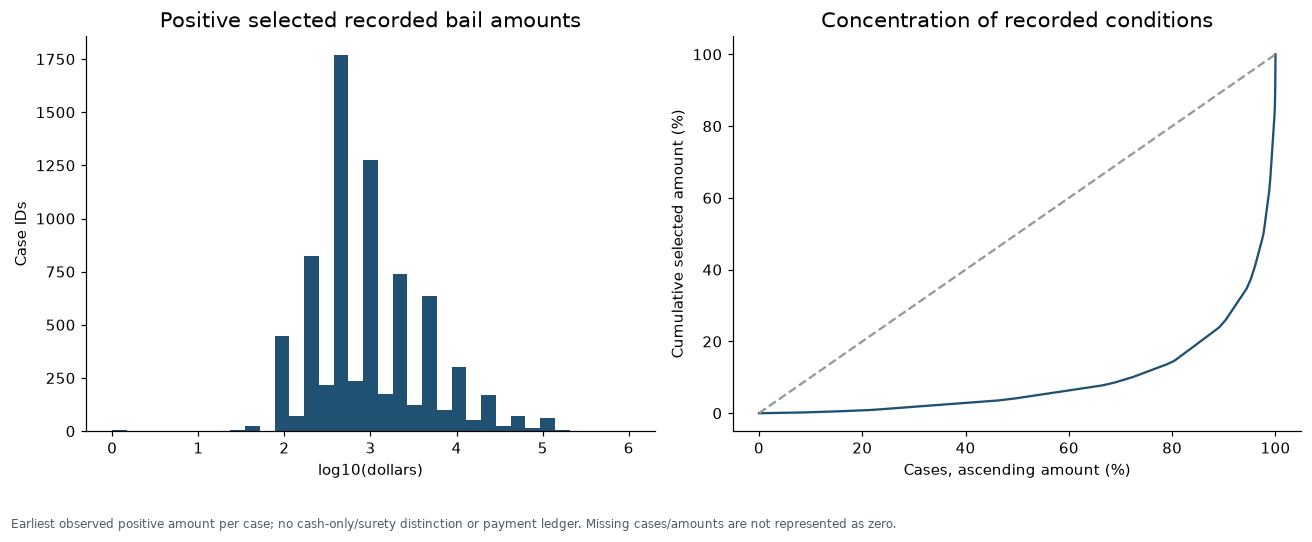

In [20]:
positive=b.loc[b.set_amount.gt(0)].sort_values(['bail_date','source_row']).drop_duplicates('case_id')
money=positive.set_amount
table('first_positive_recorded_amount_summary',money.describe(percentiles=[.25,.5,.75,.9,.99]).to_frame('dollars'))
fig,axs=plt.subplots(1,2,figsize=(12,5));axs[0].hist(np.log10(money),bins=35,color=COLORS[0])
axs[0].set(title='Positive selected recorded bail amounts',xlabel='log10(dollars)',ylabel='Case IDs')
values=np.sort(money);axs[1].plot(np.arange(len(values)+1)/len(values)*100,np.r_[0,np.cumsum(values)/values.sum()]*100)
axs[1].plot([0,100],[0,100],ls='--',color='#999');axs[1].set(title='Concentration of recorded conditions',xlabel='Cases, ascending amount (%)',ylabel='Cumulative selected amount (%)')
finish(fig,'29_monetary_condition_concentration','Earliest observed positive amount per case; no cash-only/surety distinction or payment ledger. Missing cases/amounts are not represented as zero.')
note(f'{len(positive):,} case IDs have a selected positive amount, median ${money.median():,.0f}. Their selected-condition sum is ${money.sum():,.0f}; it does not measure money paid or received.')

## 17. Bail associated with charge codes and demographics

**Purpose:** the bail file lacks Crime Type. Instead, link a first observed event to a case’s representative allegation/source class in the filing extract. These attributes are observed at extraction, not proven to have been known at that hearing. This cannot recreate a crime-type-by-cash-surety analysis.

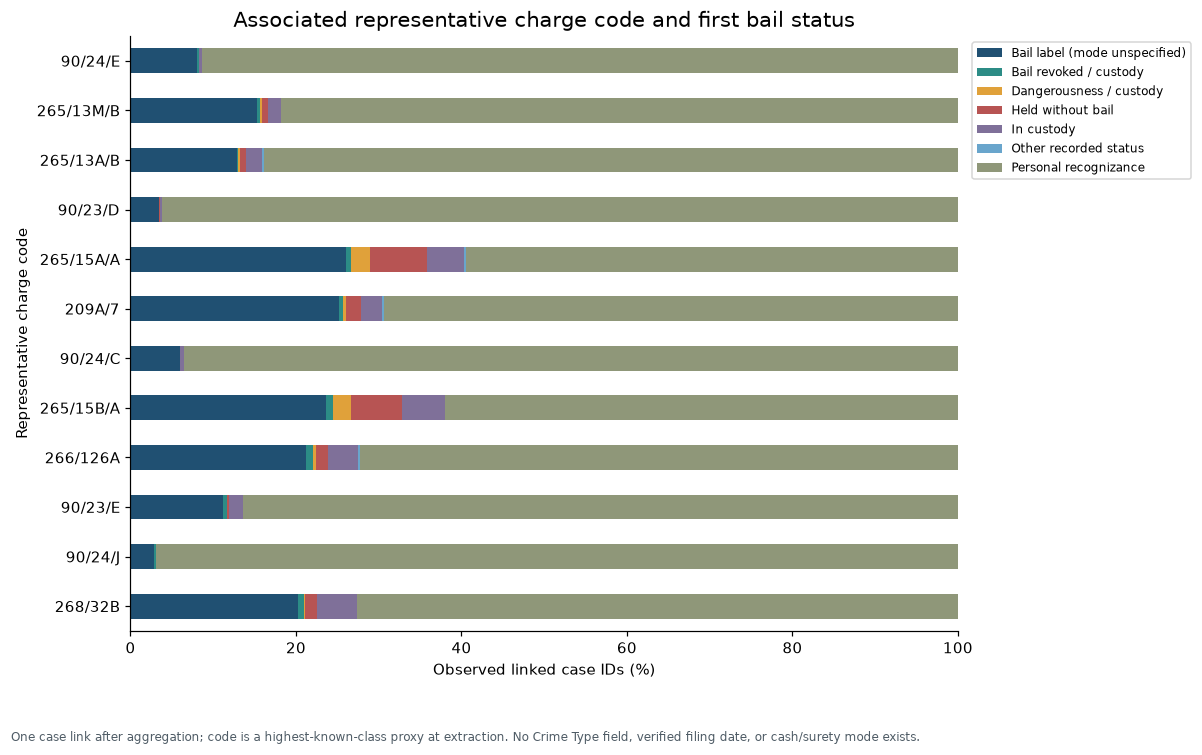

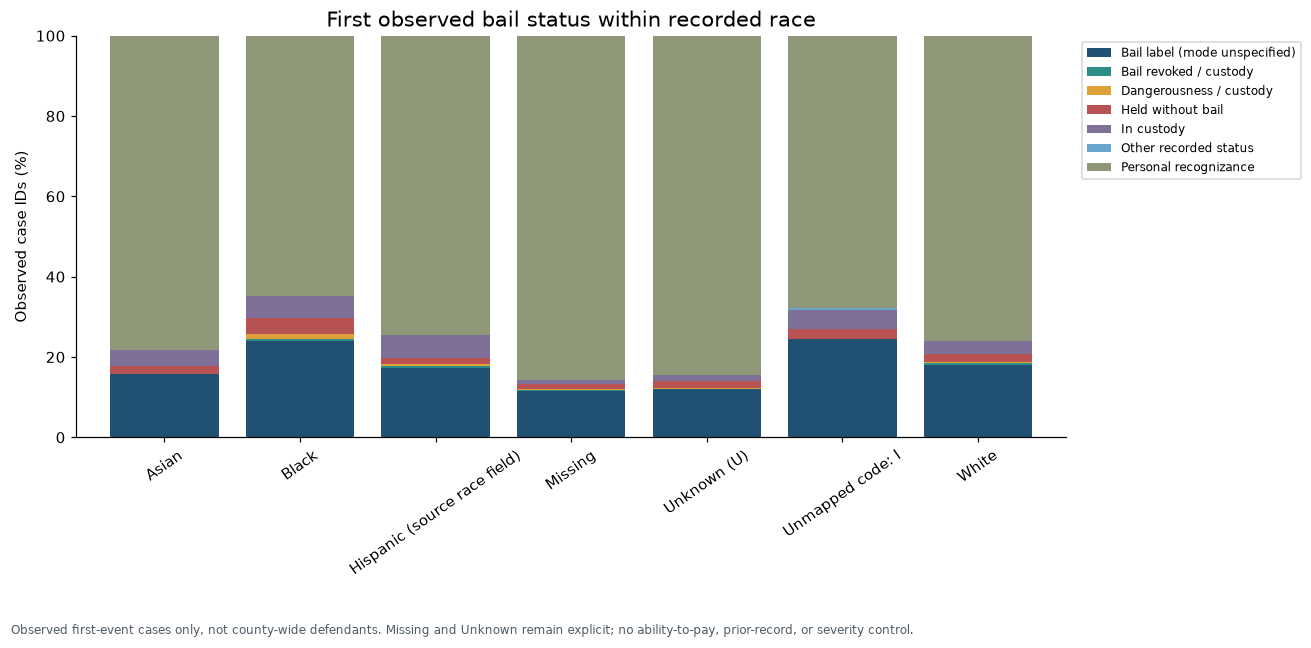

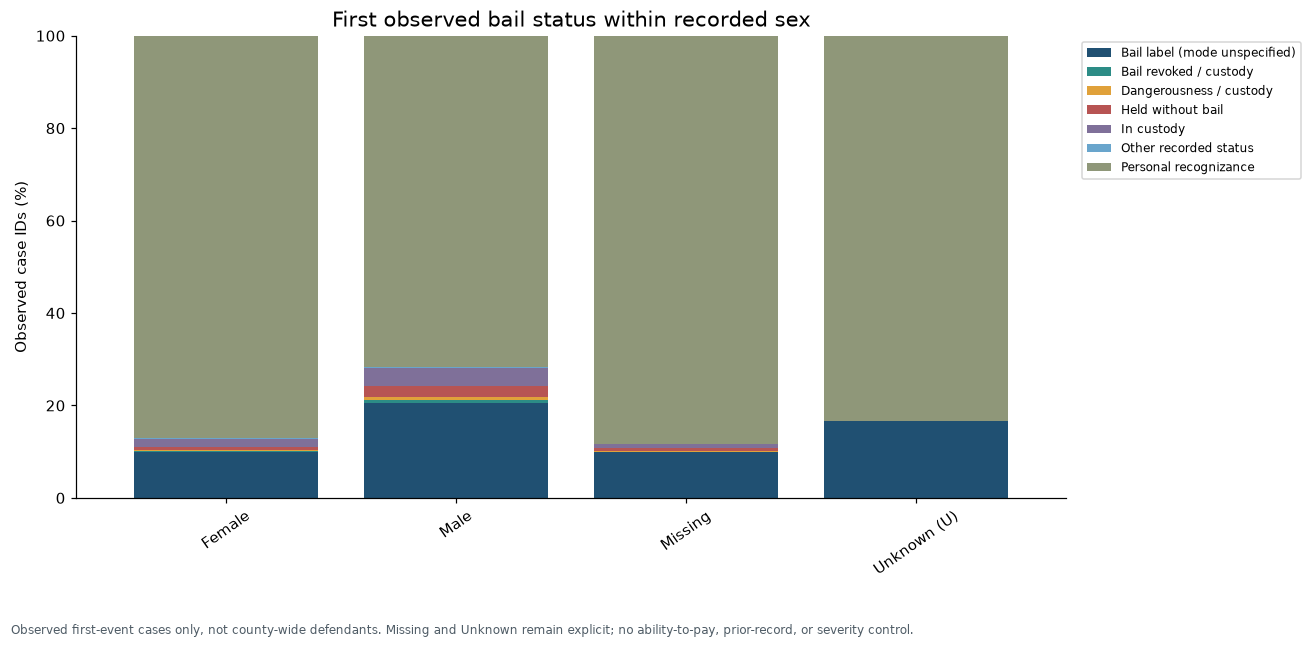

In [21]:
linked=first_link.loc[first_link.representative_code.notna()].copy()
by_code=pd.crosstab(linked.representative_code,linked.status_group)
table('associated_representative_charge_vs_first_bail',by_code,rows=20)
codes=by_code.sum(axis=1).loc[lambda s:s>=100].nlargest(12).index
plot_rates=by_code.reindex(codes).div(by_code.reindex(codes).sum(axis=1),axis=0)*100
fig,ax=plt.subplots(figsize=(11,7))
plot_rates.iloc[::-1].plot.barh(stacked=True,ax=ax,color=COLORS)
ax.set(title='Associated representative charge code and first bail status',xlabel='Observed linked case IDs (%)',ylabel='Representative charge code',xlim=(0,100))
ax.legend(title='',bbox_to_anchor=(1.01,1),loc='upper left',fontsize=8)
finish(fig,'30_associated_charge_bail_mix','One case link after aggregation; code is a highest-known-class proxy at extraction. No Crime Type field, verified filing date, or cash/surety mode exists.')
table('bail_linkage_coverage',pd.Series({'observed_first_bail_cases':len(first),'linked_to_filing_case_attributes':len(linked),
 'without_filing_attributes':len(first)-len(linked)},name='case_ids'))
for group in ['race','sex']:
    counts_group=pd.crosstab(first[group],first.status_group)
    table(f'first_bail_status_by_{group}',counts_group,rows=30)
    eligible=counts_group.sum(axis=1).loc[lambda s:s>=MIN_CELL].index
    fig,ax=stacked(counts_group.loc[eligible],f'First observed bail status within recorded {group}',percent=True)
    ax.set_ylabel('Observed case IDs (%)')
    finish(fig,f'31_first_bail_{group}','Observed first-event cases only, not county-wide defendants. Missing and Unknown remain explicit; no ability-to-pay, prior-record, or severity control.')

## 18. Case-level linkage, charge complexity, and outcome selection

**Purpose:** avoid multiplying charges by bail events or manufacturing a charge-to-charge key. Cape lacks a count sequence ID; identical charge descriptions cannot establish one-to-one charge identity. Case aggregation permits a documented descriptive link while preserving unmatched cases.

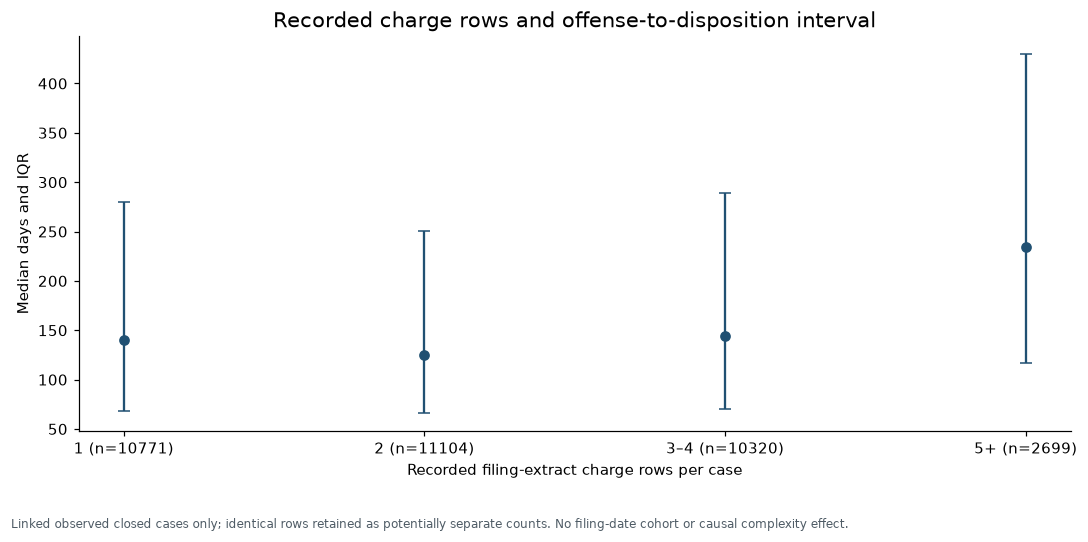

In [22]:
overlap=fc_all[['recorded_charge_rows','case_class']].merge(dc[['offense_to_disposition_days','outcome','last_disposition']],left_index=True,right_index=True,how='outer',validate='one_to_one',indicator=True)
table('case_linkage_overlap',overlap['_merge'].value_counts().to_frame('case_defendant_units'))
usable=overlap.loc[overlap['_merge'].eq('both')&overlap.offense_to_disposition_days.ge(0)].copy()
usable['burden']=pd.cut(usable.recorded_charge_rows,[0,1,2,4,np.inf],labels=['1','2','3–4','5+'])
summary=usable.groupby('burden',observed=True).offense_to_disposition_days.agg(cases='size',median='median',p25=lambda s:s.quantile(.25),p75=lambda s:s.quantile(.75))
table('case_charge_complexity_vs_offense_interval',summary)
fig,ax=plt.subplots(figsize=(10,5));ax.errorbar(range(len(summary)),summary['median'],yerr=[summary['median']-summary.p25,summary.p75-summary['median']],fmt='o',capsize=4)
ax.set_xticks(range(len(summary)),[f'{label} (n={n})' for label,n in zip(summary.index,summary.cases)])
ax.set(title='Recorded charge rows and offense-to-disposition interval',xlabel='Recorded filing-extract charge rows per case',ylabel='Median days and IQR')
finish(fig,'32_complexity_interval','Linked observed closed cases only; identical rows retained as potentially separate counts. No filing-date cohort or causal complexity effect.')
placeholders=pd.DataFrame({'filed_full':[int(f_all.charge_code.eq(x).sum()) for x in ['666666','999999']],
 'disposed_window':[int(d.charge_code.eq(x).sum()) for x in ['666666','999999']]},index=['666666','999999'])
table('placeholder_charge_codes',placeholders)
note('Case-level links are one-to-one after aggregation. Missing matches may reflect extraction scope, unresolved/later cases, old cases, changed identifiers, or recording errors; they are not automatically pending. No original arrest charge or reliable amendment history exists.')

## What must remain unresolved

Filing-date trends and filing-to-disposition delays; population rates; referral/declination rates; original-to-filed charge changes; complete program enrollment; age/prior record; actual bail payments or receipts; cash-only versus surety; full detention duration; judge causal effects; total concurrent/consecutive sentences; and a validated seriousness/category crosswalk cannot be supplied by these three extracts. The shared-Objectives notebook flags these question by question.

Missing/unmapped class and sparse sentencing information limit the selected known-criminal cohort. Cases with unresolved dates or shifted-row patterns have explicit audit counts; they are not repaired by guessing. Source class, source status, and the provisional case hierarchy should be reviewed before publishing a cross-county comparison.

In [23]:
assert len(f_all)+int((F.severe_shift|F.unattached_row).sum())==len(F)
assert len(d_all)+int((D.severe_shift|D.unattached_row).sum())==len(D)
assert int(case_out.cases.sum())==len(dc)
assert int(cmp.events.sum())==len(pair)
assert len(first_link)==len(first)
print('PASS: quarantine reconciliation, case outcome totals, paired bail totals, and one-row-per-case linkage.')

assert all(hashlib.sha256(path.read_bytes()).hexdigest()==hashes[name] for name,path in paths.items())
assert fc_all.index.is_unique and dc.index.is_unique
assert first.case_id.is_unique and first_link.case_id.is_unique
manifest={'inputs':{k:{'file':v.name,'sha256':hashes[k]} for k,v in paths.items()},
 'external_numerical_inputs':[],'filing_date_present':False,'case_ID_year_is_unverified_proxy':True,
 'source_files_unchanged':True,'identical_rows_retained':True,'quarantine_rows':len(quarantine),
 'figures':FIGURES,'tables':list(TABLES),'versions':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'matplotlib':plt.matplotlib.__version__}}
(OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf8')
(OUT/'computed_findings.md').write_text('# Cape and Islands: computed findings\n\n'+'\n\n'.join('- '+s for s in FINDINGS),encoding='utf8')
print(f'Completed: {len(FIGURES)} figures, {len(TABLES)} tables. Original hashes unchanged; no external numerical inputs.')

## Selected results from this run

### case outcome distribution

| outcome | cases | percent |
| --- | --- | --- |
| Dismissal | 21145 | 55.59 |
| CWOF | 6199 | 16.3 |
| Guilty plea | 5796 | 15.24 |
| Nolle prosequi | 1779 | 4.68 |
| Recorded pretrial probation | 1126 | 2.96 |
| Acquittal marker | 885 | 2.33 |
| Trial conviction | 629 | 1.65 |
| Juvenile adjudication | 182 | 0.48 |

[Full results table](published-results/case_outcome_distribution.csv)

### bail requested vs set paired events

| comparison | events | percent_of_paired_events |
| --- | --- | --- |
| Lower | 4687 | 55.66 |
| Equal | 3287 | 39.03 |
| Higher | 447 | 5.31 |

[Full results table](published-results/bail_requested_vs_set_paired_events.csv)
